In [1]:
# Cell 1: Load and first look
import pandas as pd
import numpy as np
import re
from collections import defaultdict

df = pd.read_csv(r'C:\Users\Lenovo\OneDrive\Desktop\CEM.csv', low_memory=False)

print("Shape (rows, columns):", df.shape)
print("\nData type counts:")
print(df.dtypes.value_counts())

total_cells = df.shape[0] * df.shape[1]
missing_cells = df.isna().sum().sum()
print(f"\nTotal cells: {total_cells:,}")
print(f"Missing cells: {missing_cells:,} ({missing_cells/total_cells*100:.1f}%)")

fully_empty = df.columns[df.isna().all()].tolist()
print(f"\nFully empty columns: {len(fully_empty)}")

Shape (rows, columns): (2506, 833)

Data type counts:
object     512
float64    183
int64      138
Name: count, dtype: int64

Total cells: 2,087,498
Missing cells: 1,504,487 (72.1%)

Fully empty columns: 121


In [2]:
#  Understand the REDCap structure (completion flags + checkbox columns)
complete_cols = [c for c in df.columns if c.endswith('_complete')]
print("Completion status columns:", complete_cols)
for col in complete_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))

print("\ncard_no dtype:", df['card_no'].dtype, "| missing:", df['card_no'].isna().sum())

Completion status columns: ['section_i_baseline_questionnaire_complete', 'section_ii_treatment_initiation_questionnaire_complete', 'section_iii_treatment_followup_questionnaire_complete', 'section_iii_treatment_followup_questionnaire_fp_complete', 'section_iv_initial_pregnancy_questionnaire_complete', 'section_vi_pregnancy_progress_questionnaire_complete', 'section_viipregnancy_outcome_questionnaire_complete']

--- section_i_baseline_questionnaire_complete ---
section_i_baseline_questionnaire_complete
2    2505
0       1
Name: count, dtype: int64

--- section_ii_treatment_initiation_questionnaire_complete ---
section_ii_treatment_initiation_questionnaire_complete
2    2491
0      15
Name: count, dtype: int64

--- section_iii_treatment_followup_questionnaire_complete ---
section_iii_treatment_followup_questionnaire_complete
2    2483
0      23
Name: count, dtype: int64

--- section_iii_treatment_followup_questionnaire_fp_complete ---
section_iii_treatment_followup_questionnaire_fp_compl

In [3]:
  #explain the 72% missingness - pregnancy/FP branching + repeat-visit structure
missing_pct = df.isna().mean().sort_values(ascending=False)
high_missing = missing_pct[missing_pct > 0.95]

def is_pregnancy_fp(col):
    c = col.lower()
    if re.search(r'\dfp|fp\d|fp_|_fp|_vi_|_vii|^vi_|^vii', c):
        return True
    keywords = ['pregnan', 'anc', 'lmp', 'delivery', 'baby', 'birth', 'infant',
                'miscarriage', 'foetal', 'breast_fee', 'woman_become', 'labour',
                'mother', 'foetus']
    return any(k in c for k in keywords)

def family_base(col):
    m = re.match(r'^(.*?)_?(\d{1,2})$', col)
    return m.group(1) if m else None

families = defaultdict(list)
for col in df.columns:
    base = family_base(col)
    if base:
        families[base].append(col)

occurrence_cols = set()
for base, cols in families.items():
    if len(cols) >= 2:
        occurrence_cols.update(cols)

pregnancy_related = [c for c in high_missing.index if is_pregnancy_fp(c)]
occurrence_related = [c for c in high_missing.index if c not in pregnancy_related and c in occurrence_cols]
remainder = [c for c in high_missing.index if c not in pregnancy_related and c not in occurrence_related]

rare_event_flags, truly_unexplained = [], []
for c in remainder:
    if df[c].dropna().nunique() <= 3:
        rare_event_flags.append(c)
    else:
        truly_unexplained.append(c)

print(f"Total >95% missing: {len(high_missing)}")
print(f"Pregnancy/FP structural: {len(pregnancy_related)}")
print(f"Repeat-visit structural: {len(occurrence_related)}")
print(f"Rare-event flags: {len(rare_event_flags)}")
print(f"Truly unexplained: {len(truly_unexplained)}")
print(truly_unexplained)

Total >95% missing: 386
Pregnancy/FP structural: 149
Repeat-visit structural: 171
Rare-event flags: 35
Truly unexplained: 31
['if_yes_fill_the_table_belo', 'age_of_the_child_months_or', 'age_of_the_child_months3', 'reason_of_stapping', 'curr_diseases3_name', 'cause_of_death', 'date_of_next_appointment_a', 'patient_hiv_clinic_no', 'tel', 'waist_circumference', 'if_yes_e_specify', 'date_most_recent_regimen_o', 'who_stage1', 'weight_kg_6', 'date_began_4', 'if_yes_where', 'patient_id_number_vi', 'date_when_movement_first_f', 'health_facility_to', 'past_diseases3_name', 'full_name', 'curr_diseases2_name', 'date_vi', 'card_no_vi', 'weight_kg_vi', 'age_vi', 'number_of_babies_delivered', 'tel_home', 'card_no_preg', 'ctel_home', 'end_medicn1_da1']


In [4]:
#  Scope down to analysis-relevant columns (CD4, viral load, WHO stage, vitals)
core_id_cols = ['card_no', 'health_facility', 'date', 'age', 'sex']
cd4_cols = [c for c in df.columns if 'test_cd4' in c.lower()]
vl_cols = [c for c in df.columns if 'viralload' in c.lower()]
who_stage_cols = [c for c in df.columns if 'who' in c.lower() and 'stage' in c.lower()]
vitals_cols = ['weight', 'height', 'bmi']

core_scope = [c for c in core_id_cols + cd4_cols + vl_cols + who_stage_cols + vitals_cols if c in df.columns]
core_df = df[core_scope].copy()
core_df['patient_id'] = core_df['health_facility'].astype(str).str.strip() + '_' + core_df['card_no'].astype(str)

print(f"Core columns: {len(core_scope)} | Core shape: {core_df.shape}")
print(f"Unique patients: {core_df['patient_id'].nunique()}")

Core columns: 69 | Core shape: (2506, 70)
Unique patients: 2506


In [5]:
#  The lab-value parser (final version - handles numbers, undetectable, not-done, typos)
UNDETECTABLE_TOKENS = {
    'nd', 'n/d', 'n.d', 'notd', 'not d', 'not det', 'not detected', 'not detect',
    'undetectable', 'undectable', 'undicatable', 'und', 'tnd', 'ldl', 'ldc',
    'undcfact', 'undecable', 'undectes', 'undectabl', 'undectale', 'undicatble',
    'undetactable', 'suppressed', 'supressed', 'suppresed', 'tdl', 'tld', 'no detected',
    'result not detected', 'ul not detected', 'n detected'
}
NOT_DONE_TOKENS = {
    'not done', 'notdone', 'note done', 'pending', 'no det', 'not available'
}
MANUAL_REVIEW_TOKENS = {
    'nod', 'no', 'new', 'cdc', 'r nat r', 'redal not recilled', 'result detected',
    're test positive', 'pegad', 'xxx', 'xxxx', 'invalid', 'undectact', 'under'
}

def tight(s):
    return re.sub(r'[^a-z0-9]', '', s)

def normalize_token(s):
    s = s.strip().lower()
    return re.sub(r'[^a-z0-9<%.,]', ' ', s).strip()

def parse_lab_value(val):
    if pd.isna(val):
        return np.nan, 'missing'

    raw = str(val).strip()
    s = normalize_token(raw)
    s_tight = tight(s)

    if s_tight in {tight(t) for t in MANUAL_REVIEW_TOKENS}:
        return np.nan, 'manual_review'
    if s_tight in {tight(t) for t in UNDETECTABLE_TOKENS} or 'notdetect' in s_tight or 'undetect' in s_tight:
        return np.nan, 'undetectable'
    if s_tight in {tight(t) for t in NOT_DONE_TOKENS}:
        return np.nan, 'not_done'

    m = re.match(r'^<\s*([\d.]+)', s)
    if m:
        return float(m.group(1)), 'below_threshold'

    s_num = s.replace(',', '')
    mult = 1
    if 'x1000000' in s_num:
        mult = 1_000_000
    elif 'x1000' in s_num:
        mult = 1000
    s_num = re.sub(r'(x\s*1?0*|mg\s*/?\s*dl|copies|copy|%|tab|tablet|ml)', '', s_num).strip()

    m = re.search(r'-?\d+\.?\d*', s_num)
    if m:
        return float(m.group()) * mult, 'numeric'

    return np.nan, 'unparsed'

# Sanity check: confirm 0 unparsed, low manual_review
result_cols = [f'test_cd4_result{n}' for n in range(1, 7)] + [f'test_viralload_result{n}' for n in range(1, 7)]
total_unparsed = sum(
    (df[col].dropna().apply(parse_lab_value).apply(lambda x: x[1] == 'unparsed')).sum()
    for col in result_cols
)
print(f"Total unparsed cells: {total_unparsed}")

Total unparsed cells: 0


In [6]:
# Cell 7: Reshape CD4 and viral load from wide to long format
def reshape_repeated_test(df, prefix, test_name, id_col='patient_id'):
    rows = []
    for n in range(1, 7):
        day_col, res_col = f'{prefix}_day{n}', f'{prefix}_result{n}'
        if day_col not in df.columns or res_col not in df.columns:
            continue
        sub = df[[id_col, day_col, res_col]].copy()
        sub = sub.dropna(subset=[res_col])
        sub['visit_number'] = n
        sub['test_date'] = pd.to_datetime(sub[day_col], format='%d/%m/%Y', errors='coerce')
        parsed = sub[res_col].apply(parse_lab_value)
        sub['value'] = parsed.apply(lambda x: x[0])
        sub['status'] = parsed.apply(lambda x: x[1])
        sub['raw_value'] = sub[res_col]
        sub['test_name'] = test_name
        rows.append(sub[[id_col, 'test_name', 'visit_number', 'test_date', 'value', 'status', 'raw_value']])
    return pd.concat(rows, ignore_index=True)

df['patient_id'] = df['health_facility'].astype(str).str.strip() + '_' + df['card_no'].astype(str)

cd4_long = reshape_repeated_test(df, 'test_cd4', 'CD4')
vl_long = reshape_repeated_test(df, 'test_viralload', 'ViralLoad')
lab_events = pd.concat([cd4_long, vl_long], ignore_index=True)
lab_events = lab_events.sort_values(['patient_id', 'test_name', 'visit_number']).reset_index(drop=True)

print("lab_events shape:", lab_events.shape)
print("Dates parsed successfully:", lab_events['test_date'].notna().sum(), "/", len(lab_events))
print(lab_events.groupby('test_name')['status'].value_counts())

lab_events shape: (5276, 7)
Dates parsed successfully: 5189 / 5276
test_name  status         
CD4        numeric            2750
           not_done            227
           undetectable         39
           manual_review         8
           below_threshold       2
ViralLoad  undetectable       1500
           numeric             329
           not_done            296
           below_threshold     111
           manual_review        14
Name: count, dtype: int64


In [7]:
# Cell 8: Investigate the suspicious duplicate-value pattern before trusting the data further
cd4_v1 = lab_events[(lab_events['test_name'] == 'CD4') & (lab_events['visit_number'] == 1)].copy()

dup_groups = cd4_v1.groupby(['test_date', 'value'])['patient_id'].nunique().sort_values(ascending=False)
print("Top (date, value) combos shared by the most DIFFERENT patients:")
print(dup_groups.head(10))

top_date, top_value = dup_groups.index[0]
suspects = cd4_v1[(cd4_v1['test_date'] == top_date) & (cd4_v1['value'] == top_value)]
print(f"\nPatients sharing date={top_date}, value={top_value}: {len(suspects)}")
print(suspects[['patient_id', 'raw_value']])

sample_ids = suspects['patient_id'].str.extract(r'_(\d+)$')[0].astype(int).tolist()[:4]
print("\nOriginal df rows for these card_nos:")
print(df[df['card_no'].isin(sample_ids)][['card_no', 'health_facility', 'age', 'sex', 'date']])

dup_card_no = df['card_no'].value_counts()
dup_card_no = dup_card_no[dup_card_no > 1]
print(f"\ncard_no values appearing more than once: {len(dup_card_no)} / {df['card_no'].nunique()}")

Top (date, value) combos shared by the most DIFFERENT patients:
test_date   value
2009-07-01  782.0    3
2008-12-04  525.0    2
2009-02-08  166.0    2
2009-09-18  673.0    2
2009-09-02  189.0    2
2009-10-02  386.0    2
2009-09-21  113.0    2
2009-04-05  750.0    2
2009-03-27  27.0     2
2009-05-15  580.0    2
Name: patient_id, dtype: int64

Patients sharing date=2009-07-01 00:00:00, value=782.0: 3
                     patient_id raw_value
3440  Saries Health Center_1186       782
3455  Saries Health Center_1210       782
3496  Saries Health Center_1255       782

Original df rows for these card_nos:
      card_no       health_facility age  sex        date
1186     1186  Saries Health Center  32  1.0  01/07/2009
1210     1210  Saries Health Center  32  1.0         NaN
1255     1255  Saries Health Center  32  1.0         NaN

card_no values appearing more than once: 1 / 2505


In [8]:
# How many such suspicious clusters exist across the WHOLE dataset (not just visit 1)?
all_lab = lab_events.dropna(subset=['test_date', 'value']).copy()
all_lab['facility'] = all_lab['patient_id'].str.rsplit('_', n=1).str[0]

cluster_sizes = (
    all_lab.groupby(['test_name', 'facility', 'test_date', 'value'])['patient_id']
    .nunique()
    .reset_index(name='n_patients')
)
suspicious_clusters = cluster_sizes[cluster_sizes['n_patients'] >= 3].sort_values('n_patients', ascending=False)

print(f"Clusters where 3+ different patients share test_name+facility+date+value: {len(suspicious_clusters)}")
print(suspicious_clusters.head(15))

# How many total test events (rows) are caught up in these suspicious clusters?
flagged_patient_ids = set()
for _, row in suspicious_clusters.iterrows():
    match = all_lab[
        (all_lab['test_name'] == row['test_name']) &
        (all_lab['facility'] == row['facility']) &
        (all_lab['test_date'] == row['test_date']) &
        (all_lab['value'] == row['value'])
    ]
    flagged_patient_ids.update(match['patient_id'])

print(f"\nTotal test events flagged as possibly templated/duplicated: {sum(cluster_sizes[cluster_sizes['n_patients']>=3]['n_patients'])}")
print(f"Total unique patients touched: {len(flagged_patient_ids)}")
print(f"As a % of all {df['patient_id'].nunique()} patients: {len(flagged_patient_ids)/df['patient_id'].nunique()*100:.2f}%")

Clusters where 3+ different patients share test_name+facility+date+value: 1
     test_name              facility  test_date  value  n_patients
1671       CD4  Saries Health Center 2009-07-01  782.0           3

Total test events flagged as possibly templated/duplicated: 3
Total unique patients touched: 3
As a % of all 2506 patients: 0.12%


In [9]:
# Add a data_quality_flag column to lab_events - visible, not deleted
suspicious_ids = set(all_lab[
    (all_lab['test_name'] == 'CD4') &
    (all_lab['facility'] == 'Saries Health Center') &
    (all_lab['test_date'] == pd.Timestamp('2009-07-01')) &
    (all_lab['value'] == 782.0)
]['patient_id'])

lab_events['data_quality_flag'] = lab_events['patient_id'].isin(suspicious_ids)
lab_events['data_quality_flag'] = lab_events['data_quality_flag'].map(
    {True: 'possible_templated_duplicate', False: None}
)

print("Flagged rows:")
print(lab_events[lab_events['data_quality_flag'].notna()])

print(f"\nFinal lab_events shape: {lab_events.shape}")
print(f"Rows flagged: {lab_events['data_quality_flag'].notna().sum()} / {len(lab_events)} ({lab_events['data_quality_flag'].notna().sum()/len(lab_events)*100:.2f}%)")

Flagged rows:
                     patient_id test_name  visit_number  test_date  value  \
3440  Saries Health Center_1186       CD4             1 2009-07-01  782.0   
3455  Saries Health Center_1210       CD4             1 2009-07-01  782.0   
3496  Saries Health Center_1255       CD4             1 2009-07-01  782.0   

       status raw_value             data_quality_flag  
3440  numeric       782  possible_templated_duplicate  
3455  numeric       782  possible_templated_duplicate  
3496  numeric       782  possible_templated_duplicate  

Final lab_events shape: (5276, 8)
Rows flagged: 3 / 5276 (0.06%)


In [10]:
# --- 1. CD4 trend: first vs last numeric value per patient ---
cd4_valid = lab_events[
    (lab_events['test_name'] == 'CD4') &
    (lab_events['status'] == 'numeric') &
    (lab_events['test_date'].notna())
].sort_values(['patient_id', 'test_date'])

def cd4_summary(g):
    return pd.Series({
        'n_tests': len(g),
        'first_date': g['test_date'].iloc[0],
        'first_value': g['value'].iloc[0],
        'last_date': g['test_date'].iloc[-1],
        'last_value': g['value'].iloc[-1],
        'change': g['value'].iloc[-1] - g['value'].iloc[0],
    })

cd4_trend = cd4_valid.groupby('patient_id').apply(cd4_summary).reset_index()
cd4_trend['direction'] = np.select(
    [cd4_trend['change'] > 0, cd4_trend['change'] < 0, cd4_trend['change'] == 0],
    ['improved', 'declined', 'no_change'],
    default='single_test_only'
)
cd4_trend.loc[cd4_trend['n_tests'] == 1, 'direction'] = 'single_test_only'

print("=== CD4 Trend Summary ===")
print(f"Patients with at least 1 valid CD4 result: {len(cd4_trend)}")
print(f"Patients with 2+ tests (real trend available): {(cd4_trend['n_tests'] >= 2).sum()}")
print("\nDirection breakdown (patients with 2+ tests only):")
print(cd4_trend[cd4_trend['n_tests'] >= 2]['direction'].value_counts())
print("\nSample rows:")
print(cd4_trend.head(10))

# --- 2. Viral load suppression rate per patient ---
vl_valid = lab_events[
    (lab_events['test_name'] == 'ViralLoad') &
    (lab_events['status'].isin(['numeric', 'undetectable', 'below_threshold']))
].copy()

vl_valid['is_suppressed'] = vl_valid['status'].isin(['undetectable', 'below_threshold'])

vl_summary = vl_valid.groupby('patient_id').agg(
    n_tests=('status', 'count'),
    n_suppressed=('is_suppressed', 'sum')
).reset_index()
vl_summary['suppression_rate'] = vl_summary['n_suppressed'] / vl_summary['n_tests']

print("\n\n=== Viral Load Suppression Summary ===")
print(f"Patients with at least 1 valid viral load result: {len(vl_summary)}")
print(f"Overall suppression rate across all valid tests: {vl_valid['is_suppressed'].mean()*100:.1f}%")
print("\nSample rows:")
print(vl_summary.head(10))
print("\nDistribution of suppression_rate:")
print(vl_summary['suppression_rate'].describe())

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14188\3234691877.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cd4_trend = cd4_valid.groupby('patient_id').apply(cd4_summary).reset_index()


=== CD4 Trend Summary ===
Patients with at least 1 valid CD4 result: 1817
Patients with 2+ tests (real trend available): 680

Direction breakdown (patients with 2+ tests only):
direction
improved     520
declined     152
no_change      8
Name: count, dtype: int64

Sample rows:
                        patient_id  n_tests first_date  first_value  \
0  Addis Ketema Health Center_2305        1 2009-09-18        673.0   
1  Addis Ketema Health Center_2306        1 2009-12-22        304.0   
2  Addis Ketema Health Center_2308        1 2009-03-02       1278.0   
3  Addis Ketema Health Center_2333        1 2010-01-23        523.0   
4   Addis Ketema Health Center_285        1 2009-03-02       1278.0   
5   Addis Ketema Health Center_286        1 2009-09-18        673.0   
6   Addis Ketema Health Center_287        1 2004-12-22        304.0   
7   Addis Ketema Health Center_289        1 2010-01-23        523.0   
8   Addis Ketema Health Center_617        2 2009-01-05        532.0   
9   Addis Ke

In [11]:
cd4_trend = cd4_valid.groupby('patient_id').apply(cd4_summary, include_groups=False).reset_index()

In [12]:
cd4_trend.to_csv('cd4_trend_summary.csv', index=False)
vl_summary.to_csv('vl_suppression_summary.csv', index=False)
lab_events.to_csv('lab_events_clean.csv', index=False)

print("Saved: cd4_trend_summary.csv, vl_suppression_summary.csv, lab_events_clean.csv")

Saved: cd4_trend_summary.csv, vl_suppression_summary.csv, lab_events_clean.csv


In [13]:
# Rebuild cd4_trend with the direction column included
cd4_valid = lab_events[
    (lab_events['test_name'] == 'CD4') &
    (lab_events['status'] == 'numeric') &
    (lab_events['test_date'].notna())
].sort_values(['patient_id', 'test_date'])

def cd4_summary(g):
    return pd.Series({
        'n_tests': len(g),
        'first_date': g['test_date'].iloc[0],
        'first_value': g['value'].iloc[0],
        'last_date': g['test_date'].iloc[-1],
        'last_value': g['value'].iloc[-1],
        'change': g['value'].iloc[-1] - g['value'].iloc[0],
    })

cd4_trend = cd4_valid.groupby('patient_id').apply(cd4_summary, include_groups=False).reset_index()

cd4_trend['direction'] = np.select(
    [cd4_trend['change'] > 0, cd4_trend['change'] < 0, cd4_trend['change'] == 0],
    ['improved', 'declined', 'no_change'],
    default='single_test_only'
)
cd4_trend.loc[cd4_trend['n_tests'] == 1, 'direction'] = 'single_test_only'

print(cd4_trend.columns.tolist())
print(cd4_trend['direction'].value_counts())

['patient_id', 'n_tests', 'first_date', 'first_value', 'last_date', 'last_value', 'change', 'direction']
direction
single_test_only    1137
improved             520
declined             152
no_change              8
Name: count, dtype: int64


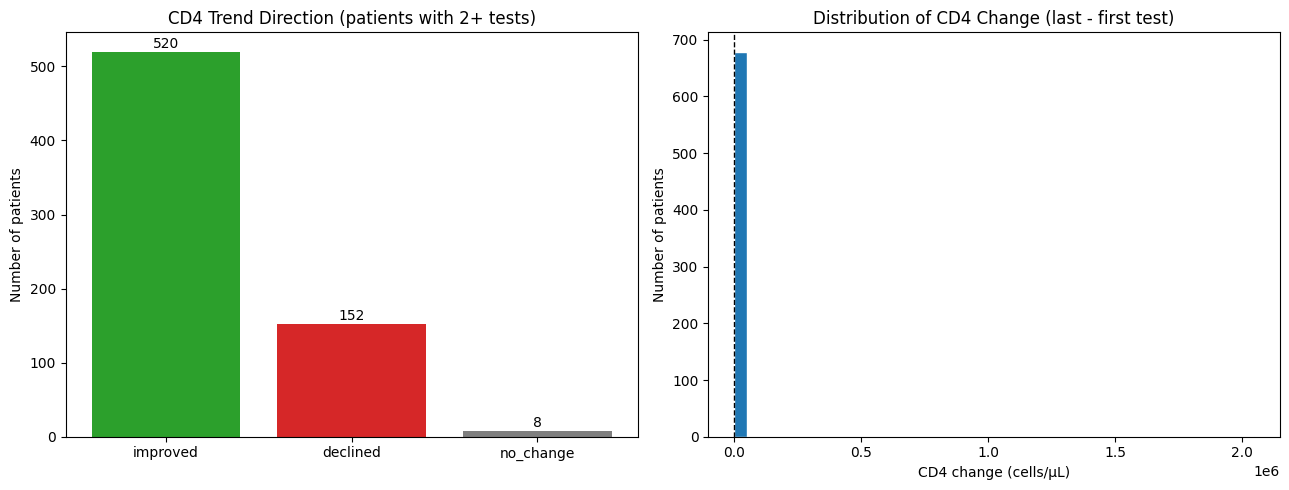

Median CD4 change: 91.5
Mean CD4 change: 3114.0773676470585


In [14]:
import matplotlib.pyplot as plt

# Only patients with a real 2+ test trend
trend_df = cd4_trend[cd4_trend['n_tests'] >= 2].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: direction breakdown
direction_counts = trend_df['direction'].value_counts()
axes[0].bar(direction_counts.index, direction_counts.values, color=['#2ca02c', '#d62728', '#7f7f7f'])
axes[0].set_title('CD4 Trend Direction (patients with 2+ tests)')
axes[0].set_ylabel('Number of patients')
for i, v in enumerate(direction_counts.values):
    axes[0].text(i, v + 5, str(v), ha='center')

# Chart 2: distribution of the actual change amount
axes[1].hist(trend_df['change'], bins=40, color='#1f77b4', edgecolor='white')
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Distribution of CD4 Change (last - first test)')
axes[1].set_xlabel('CD4 change (cells/µL)')
axes[1].set_ylabel('Number of patients')

plt.tight_layout()
plt.savefig('cd4_trend_charts.png', dpi=150)
plt.show()

print("Median CD4 change:", trend_df['change'].median())
print("Mean CD4 change:", trend_df['change'].mean())

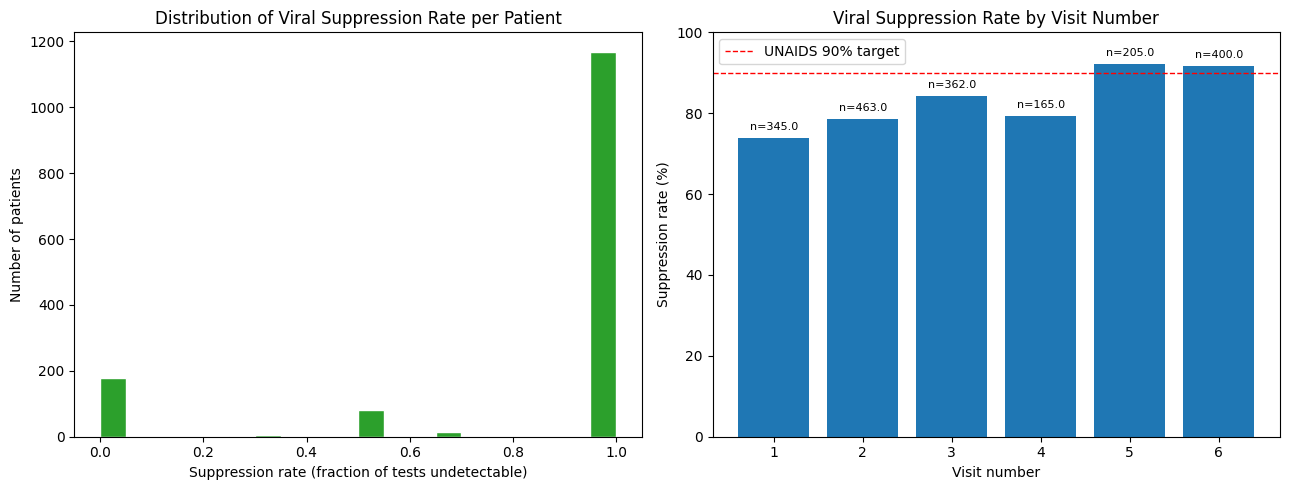

   visit_number  n_tests  suppression_rate
0             1      345          0.739130
1             2      463          0.786177
2             3      362          0.842541
3             4      165          0.793939
4             5      205          0.921951
5             6      400          0.917500


In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: distribution of suppression_rate across patients
axes[0].hist(vl_summary['suppression_rate'], bins=20, color='#2ca02c', edgecolor='white')
axes[0].set_title('Distribution of Viral Suppression Rate per Patient')
axes[0].set_xlabel('Suppression rate (fraction of tests undetectable)')
axes[0].set_ylabel('Number of patients')

# Chart 2: suppression rate by visit number (does it improve over time on treatment?)
vl_by_visit = vl_valid.groupby('visit_number').agg(
    n_tests=('is_suppressed', 'count'),
    suppression_rate=('is_suppressed', 'mean')
).reset_index()

axes[1].bar(vl_by_visit['visit_number'], vl_by_visit['suppression_rate'] * 100, color='#1f77b4')
axes[1].set_title('Viral Suppression Rate by Visit Number')
axes[1].set_xlabel('Visit number')
axes[1].set_ylabel('Suppression rate (%)')
axes[1].set_ylim(0, 100)
axes[1].axhline(90, color='red', linestyle='--', linewidth=1, label='UNAIDS 90% target')
axes[1].legend()

for i, row in vl_by_visit.iterrows():
    axes[1].text(row['visit_number'], row['suppression_rate']*100 + 2, f"n={row['n_tests']}", ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('viral_load_charts.png', dpi=150)
plt.show()

print(vl_by_visit)

In [16]:
# 1. Add a plausibility flag to lab_events for CD4 results above a clinical ceiling
CD4_CEILING = 2500  # cells/uL - values above this are treated as implausible/likely miscoded

cd4_mask = (lab_events['test_name'] == 'CD4') & (lab_events['value'] > CD4_CEILING)
lab_events.loc[cd4_mask, 'data_quality_flag'] = 'implausible_cd4_value'

print("Rows flagged as implausible CD4:")
print(lab_events[lab_events['data_quality_flag'] == 'implausible_cd4_value']
      [['patient_id', 'visit_number', 'value', 'raw_value', 'test_date']])

# 2. Rebuild the visit-level CD4 summary EXCLUDING flagged rows, so the chart is trustworthy
cd4_numeric_clean = lab_events[
    (lab_events['test_name'] == 'CD4') &
    (lab_events['status'] == 'numeric') &
    (lab_events['data_quality_flag'].isna())
]

cd4_by_visit_clean = cd4_numeric_clean.groupby('visit_number').agg(
    n_tests=('value', 'count'),
    mean_cd4=('value', 'mean'),
    median_cd4=('value', 'median')
).reset_index()

print("\nCD4 by visit, after excluding implausible values:")
print(cd4_by_visit_clean)

Rows flagged as implausible CD4:
                   patient_id  visit_number      value       raw_value  \
322        Alert Hospital_681             1     3106.0            3106   
1422  Kolfe Health Center_139             1     3844.0            3844   
2665    Menelik Hospital_2362             6  2046378.0  2046378 copies   
4690    Zewditu Hospital_1491             4     2591.0            2591   
4849    Zewditu Hospital_1554             6     2781.0            2781   

      test_date  
322  2009-04-04  
1422 2009-04-26  
2665 2012-05-13  
4690 2010-09-22  
4849 2010-05-24  

CD4 by visit, after excluding implausible values:
   visit_number  n_tests    mean_cd4  median_cd4
0             1     1652  335.254013       255.5
1             2      403  399.486452       327.0
2             3      277  369.292058       325.0
3             4      118  410.271186       342.0
4             5      118  389.462712       351.5
5             6      174  422.622414       369.5


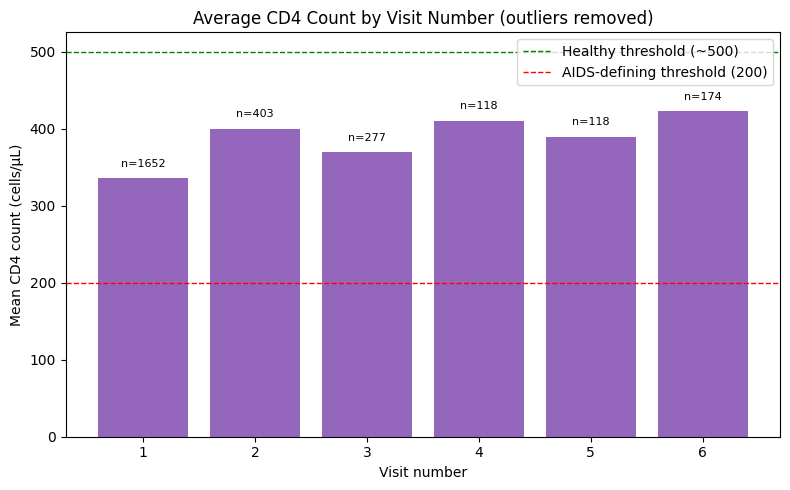

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(cd4_by_visit_clean['visit_number'], cd4_by_visit_clean['mean_cd4'], color='#9467bd')
ax.axhline(500, color='green', linestyle='--', linewidth=1, label='Healthy threshold (~500)')
ax.axhline(200, color='red', linestyle='--', linewidth=1, label='AIDS-defining threshold (200)')
ax.set_title('Average CD4 Count by Visit Number (outliers removed)')
ax.set_xlabel('Visit number')
ax.set_ylabel('Mean CD4 count (cells/µL)')
ax.legend()

for i, row in cd4_by_visit_clean.iterrows():
    ax.text(row['visit_number'], row['mean_cd4'] + 15, f"n={int(row['n_tests'])}", ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('cd4_by_visit_chart_clean.png', dpi=150)
plt.show()

In [18]:
import re
from collections import defaultdict

# Find every column matching the pattern testname_result{n} or testname_day{n}
result_pattern = re.compile(r'^test_(.+?)_result(\d+)$')
day_pattern = re.compile(r'^test_(.+?)_day(\d+)$')

panels = defaultdict(set)
for col in df.columns:
    m = result_pattern.match(col) or day_pattern.match(col)
    if m:
        panels[m.group(1)].add(int(m.group(2)))

print(f"Total lab panels found: {len(panels)}\n")
for panel, visits in sorted(panels.items()):
    print(f"{panel:20s} -> visits recorded: {sorted(visits)}")

Total lab panels found: 19

alt_sgpt             -> visits recorded: [1, 2, 3, 4, 5, 6]
astsgot              -> visits recorded: [1, 2, 3, 4, 5, 6]
basiophils           -> visits recorded: [1, 2, 3, 4, 5, 6]
bilirubin            -> visits recorded: [1, 2, 3, 4, 5, 6]
bunurea              -> visits recorded: [1, 2, 3, 4, 5, 6]
cd4                  -> visits recorded: [1, 2, 3, 4, 5, 6]
creatinine           -> visits recorded: [1, 2, 3, 4, 5, 6]
eonsionp             -> visits recorded: [1, 2, 3, 4, 5, 6]
glucose              -> visits recorded: [1, 2, 3, 4, 5, 6]
hemat                -> visits recorded: [1, 2, 3, 4, 5, 6]
lymphoc              -> visits recorded: [1, 2, 3, 4, 5, 6]
monocytes            -> visits recorded: [1, 2, 3, 4, 5, 6]
neutrop              -> visits recorded: [1, 2, 3, 4, 5, 6]
platelates           -> visits recorded: [1, 2, 3, 4, 5, 6]
rbsc                 -> visits recorded: [1, 2, 3, 4, 5, 6]
triglyceride         -> visits recorded: [1, 2, 3, 4, 5, 6]
twbc        

In [19]:
import re
from collections import defaultdict

# Find every column matching the pattern testname_result{n} or testname_day{n}
result_pattern = re.compile(r'^test_(.+?)_result(\d+)$')
day_pattern = re.compile(r'^test_(.+?)_day(\d+)$')

panels = defaultdict(set)
for col in df.columns:
    m = result_pattern.match(col) or day_pattern.match(col)
    if m:
        panels[m.group(1)].add(int(m.group(2)))

print(f"Total lab panels found: {len(panels)}\n")
for panel, visits in sorted(panels.items()):
    print(f"{panel:20s} -> visits recorded: {sorted(visits)}")

Total lab panels found: 19

alt_sgpt             -> visits recorded: [1, 2, 3, 4, 5, 6]
astsgot              -> visits recorded: [1, 2, 3, 4, 5, 6]
basiophils           -> visits recorded: [1, 2, 3, 4, 5, 6]
bilirubin            -> visits recorded: [1, 2, 3, 4, 5, 6]
bunurea              -> visits recorded: [1, 2, 3, 4, 5, 6]
cd4                  -> visits recorded: [1, 2, 3, 4, 5, 6]
creatinine           -> visits recorded: [1, 2, 3, 4, 5, 6]
eonsionp             -> visits recorded: [1, 2, 3, 4, 5, 6]
glucose              -> visits recorded: [1, 2, 3, 4, 5, 6]
hemat                -> visits recorded: [1, 2, 3, 4, 5, 6]
lymphoc              -> visits recorded: [1, 2, 3, 4, 5, 6]
monocytes            -> visits recorded: [1, 2, 3, 4, 5, 6]
neutrop              -> visits recorded: [1, 2, 3, 4, 5, 6]
platelates           -> visits recorded: [1, 2, 3, 4, 5, 6]
rbsc                 -> visits recorded: [1, 2, 3, 4, 5, 6]
triglyceride         -> visits recorded: [1, 2, 3, 4, 5, 6]
twbc        

In [20]:
# For each panel, sample raw result values to see how messy the text actually is
for panel in sorted(panels.keys()):
    if panel in ('cd4', 'viralload'):
        continue  # already done
    col = f'test_{panel}_result1'
    if col not in df.columns:
        continue
    sample_vals = df[col].dropna().unique()
    print(f"\n=== {panel} ({len(sample_vals)} unique values) ===")
    print(sample_vals[:12])


=== alt_sgpt (481 unique values) ===
['44' '21' '13 u/d' '12.8' '12' '23' '65.4' '43' '15.3' '22' '34.7' '11.8']

=== astsgot (482 unique values) ===
['48' '12' '11' '10 u/l' '26.9' '16.5' '44' '62.5' '34' '18.7' '22' '16']

=== basiophils (239 unique values) ===
['2.542' '0.94' '0.937' '0.4' '0.945' '0.9' '0.3' '1.25' '0.5' '1.11'
 '1.14' '1.75']

=== bilirubin (105 unique values) ===
['0.334' '0.58' '0.143' '1.01' '0.616' '0.124' '0.22' '0.32' '0.18' '0.16'
 '0.7' '1.06']

=== bunurea (349 unique values) ===
['116' '21' '12.9' '19.8' '18.6' '8.7' '16.7' '14' '18.5' '16.5' '20.9'
 '30']

=== creatinine (242 unique values) ===
['2.4' '1' '0.4' '0.6' '0.63' '0.32' '0.67' '0.8' '0.68' '0.5' '0.41'
 '0.58']

=== eonsionp (324 unique values) ===
['0.673' '6.8' '0.305' '2.5' '8.17' '0.5' '3.09' '4.7' '0.024' '0' '3.81'
 '11.95']

=== glucose (186 unique values) ===
['103' '133' '20' 'neg' '110' '155.5' '195' '107' '121' '115' '111' '82']

=== hemat (1032 unique values) ===
['12.8' '38.6' '

In [21]:
# Extend the existing parser with new unit suffixes, negative-result handling,
# spreadsheet-error detection, and explicit handling for combined hemat/hgb values

SPREADSHEET_ERROR_TOKENS = {'#name?', '#value?', '#ref!', '#div/0!', '#n/a', '#null!'}
NEGATIVE_RESULT_TOKENS = {'neg', 'negative', 'no', 'none', 'nil'}

def parse_lab_value_v2(val, allow_combined=False):
    """
    Extended parser. If allow_combined=True and the value looks like 'X/Y'
    (e.g. hematocrit/hemoglobin), returns BOTH numbers with status 'combined_value'
    instead of guessing which one matters.
    """
    if pd.isna(val):
        return np.nan, 'missing'

    raw = str(val).strip()
    s = normalize_token(raw)
    s_tight = tight(s)

    if s_tight in {tight(t) for t in SPREADSHEET_ERROR_TOKENS}:
        return np.nan, 'spreadsheet_error'
    if s_tight in {tight(t) for t in NEGATIVE_RESULT_TOKENS}:
        return 0.0, 'negative_result'
    if s_tight in {tight(t) for t in MANUAL_REVIEW_TOKENS}:
        return np.nan, 'manual_review'
    if s_tight in {tight(t) for t in UNDETECTABLE_TOKENS} or 'notdetect' in s_tight or 'undetect' in s_tight:
        return np.nan, 'undetectable'
    if s_tight in {tight(t) for t in NOT_DONE_TOKENS}:
        return np.nan, 'not_done'

    # Combined "X/Y" values (e.g. hematocrit/hemoglobin) - don't guess, flag both numbers
    if allow_combined:
        m = re.match(r'^(\d+\.?\d*)\s*/\s*(\d+\.?\d*)$', raw.strip())
        if m:
            return (float(m.group(1)), float(m.group(2))), 'combined_value'

    m = re.match(r'^<\s*([\d.]+)', s)
    if m:
        return float(m.group(1)), 'below_threshold'

    s_num = s.replace(',', '')
    mult = 1
    if 'x1000000' in s_num:
        mult = 1_000_000
    elif 'x1000' in s_num:
        mult = 1000
    # Now strips u/l, u/d too, alongside the units we already handled
    s_num = re.sub(r'(x\s*1?0*|mg\s*/?\s*dl|u\s*/\s*[ld]|copies|copy|%|tab|tablet|ml)', '', s_num).strip()

    m = re.search(r'-?\d+\.?\d*', s_num)
    if m:
        return float(m.group()) * mult, 'numeric'

    return np.nan, 'unparsed'


# Check unparsed rate across ALL 19 panels now
all_result_cols = []
for panel in panels:
    for n in range(1, 7):
        col = f'test_{panel}_result{n}'
        if col in df.columns:
            all_result_cols.append((panel, col))

print("=== Unparsed values per panel (target: near zero) ===")
for panel, col in all_result_cols:
    is_hemat = (panel == 'hemat')
    results = df[col].dropna().apply(lambda v: parse_lab_value_v2(v, allow_combined=is_hemat))
    unparsed_vals = df[col].dropna()[[r[1] == 'unparsed' for r in results]].unique()
    if len(unparsed_vals) > 0:
        print(f"{panel} ({col}): {unparsed_vals[:10]}")

=== Unparsed values per panel (target: near zero) ===
hemat (test_hemat_result2): ['DNAPCR +ve']
neutrop (test_neutrop_result1): ['not' 'not lead']
neutrop (test_neutrop_result2): ['not load']
lymphoc (test_lymphoc_result1): ['low']
lymphoc (test_lymphoc_result5): ['N/aual (not done)']
basiophils (test_basiophils_result1): ['not lead' 'Q']
basiophils (test_basiophils_result5): ['N/aual (not done)']
monocytes (test_monocytes_result1): ['not lead' 'low' 'Q']
monocytes (test_monocytes_result5): ['N/aual (not done)']
eonsionp (test_eonsionp_result1): ['low']
eonsionp (test_eonsionp_result3): ['N/L']
eonsionp (test_eonsionp_result5): ['N/aual (not done)']
rbsc (test_rbsc_result1): ['normal' 'mony']
rbsc (test_rbsc_result5): ['N/aual (not done)']
platelates (test_platelates_result1): ['Q']
platelates (test_platelates_result5): ['N/aual (not done)']
alt_sgpt (test_alt_sgpt_result1): ['NR']
alt_sgpt (test_alt_sgpt_result2): ['NL']
astsgot (test_astsgot_result1): ['normal' 'NR']
glucose (test_g

In [22]:
QUALITATIVE_TOKENS = {'normal', 'noraml', 'low', 'trace', 'nr', 'nl', 'wnl', 'high'}
UNIT_ONLY_TOKENS = {'mg/dl', 'mgdl', 'ul', 'mg', 'dl', 'ml'}
NEGATIVE_DASH = {'-'}
WRONG_FIELD_TOKENS = {'dnapcr +ve', 'dnapcr+ve', 'vl ldl', 'vlldl'}

NOT_DONE_TOKENS_V2 = NOT_DONE_TOKENS | {'not lead', 'not load', 'nt done', 'not read'}

def parse_lab_value_v3(val, allow_combined=False):
    if pd.isna(val):
        return np.nan, 'missing'

    raw = str(val).strip()
    s = normalize_token(raw)
    s_tight = tight(s)
    s_lower = raw.lower()

    if s_tight in {tight(t) for t in SPREADSHEET_ERROR_TOKENS}:
        return np.nan, 'spreadsheet_error'
    if s_tight in {tight(t) for t in WRONG_FIELD_TOKENS} or 'dnapcr' in s_tight:
        return np.nan, 'wrong_field_contamination'
    if '(not done)' in s_lower or s_tight in {tight(t) for t in NOT_DONE_TOKENS_V2}:
        return np.nan, 'not_done'
    if s_tight in {tight(t) for t in QUALITATIVE_TOKENS}:
        return np.nan, 'qualitative_result'
    if s_tight in {tight(t) for t in UNIT_ONLY_TOKENS}:
        return np.nan, 'missing'
    if raw.strip() in NEGATIVE_DASH:
        return 0.0, 'negative_result'
    if s_tight in {tight(t) for t in NEGATIVE_RESULT_TOKENS}:
        return 0.0, 'negative_result'
    if s_tight in {tight(t) for t in MANUAL_REVIEW_TOKENS}:
        return np.nan, 'manual_review'
    if s_tight in {tight(t) for t in UNDETECTABLE_TOKENS} or 'notdetect' in s_tight or 'undetect' in s_tight:
        return np.nan, 'undetectable'

    if allow_combined:
        m = re.match(r'^(\d+\.?\d*)\s*/\s*(\d+\.?\d*)$', raw.strip())
        if m:
            return (float(m.group(1)), float(m.group(2))), 'combined_value'

    m = re.match(r'^<\s*([\d.]+)', s)
    if m:
        return float(m.group(1)), 'below_threshold'

    s_num = s.replace(',', '')
    mult = 1
    if 'x1000000' in s_num:
        mult = 1_000_000
    elif 'x1000' in s_num:
        mult = 1000
    s_num = re.sub(r'(x\s*1?0*|mg\s*/?\s*dl|u\s*/\s*[ld]|copies|copy|%|tab|tablet|ml)', '', s_num).strip()

    m = re.search(r'-?\d+\.?\d*', s_num)
    if m:
        return float(m.group()) * mult, 'numeric'

    return np.nan, 'unparsed', raw  # keep raw for anything still slipping through


# Re-check unparsed rate
print("=== Unparsed values remaining (target: zero) ===")
total_unparsed = 0
for panel, col in all_result_cols:
    is_hemat = (panel == 'hemat')
    results = df[col].dropna().apply(lambda v: parse_lab_value_v3(v, allow_combined=is_hemat))
    unparsed_vals = df[col].dropna()[[r[1] == 'unparsed' for r in results]].unique()
    if len(unparsed_vals) > 0:
        print(f"{panel} ({col}): {unparsed_vals}")
        total_unparsed += len(unparsed_vals)
print(f"\nTotal unparsed value types remaining: {total_unparsed}")

# Also show what fell into the new categories, so we can sanity check them
print("\n=== Wrong-field contamination found ===")
for panel, col in all_result_cols:
    results = df[col].dropna().apply(lambda v: parse_lab_value_v3(v)[1])
    n = (results == 'wrong_field_contamination').sum()
    if n > 0:
        print(f"{panel}: {n} rows")

=== Unparsed values remaining (target: zero) ===
neutrop (test_neutrop_result1): ['not']
basiophils (test_basiophils_result1): ['Q']
monocytes (test_monocytes_result1): ['Q']
rbsc (test_rbsc_result1): ['mony']
platelates (test_platelates_result1): ['Q']
glucose (test_glucose_result5): ['yes']
glucose (test_glucose_result6): ['yes']

Total unparsed value types remaining: 7

=== Wrong-field contamination found ===
hemat: 1 rows
urinealbumin: 1 rows


In [23]:
FINAL_MANUAL_REVIEW = MANUAL_REVIEW_TOKENS | {'q', 'mony', 'not', 'yes'}

def parse_lab_value_final(val, allow_combined=False):
    if pd.isna(val):
        return np.nan, 'missing'

    raw = str(val).strip()
    s = normalize_token(raw)
    s_tight = tight(s)
    s_lower = raw.lower()

    if s_tight in {tight(t) for t in SPREADSHEET_ERROR_TOKENS}:
        return np.nan, 'spreadsheet_error'
    if s_tight in {tight(t) for t in WRONG_FIELD_TOKENS} or 'dnapcr' in s_tight:
        return np.nan, 'wrong_field_contamination'
    if '(not done)' in s_lower or s_tight in {tight(t) for t in NOT_DONE_TOKENS_V2}:
        return np.nan, 'not_done'
    if s_tight in {tight(t) for t in QUALITATIVE_TOKENS}:
        return np.nan, 'qualitative_result'
    if s_tight in {tight(t) for t in UNIT_ONLY_TOKENS}:
        return np.nan, 'missing'
    if raw.strip() in NEGATIVE_DASH:
        return 0.0, 'negative_result'
    if s_tight in {tight(t) for t in NEGATIVE_RESULT_TOKENS}:
        return 0.0, 'negative_result'
    if s_tight in {tight(t) for t in FINAL_MANUAL_REVIEW}:
        return np.nan, 'manual_review'
    if s_tight in {tight(t) for t in UNDETECTABLE_TOKENS} or 'notdetect' in s_tight or 'undetect' in s_tight:
        return np.nan, 'undetectable'

    if allow_combined:
        m = re.match(r'^(\d+\.?\d*)\s*/\s*(\d+\.?\d*)$', raw.strip())
        if m:
            return (float(m.group(1)), float(m.group(2))), 'combined_value'

    m = re.match(r'^<\s*([\d.]+)', s)
    if m:
        return float(m.group(1)), 'below_threshold'

    s_num = s.replace(',', '')
    mult = 1
    if 'x1000000' in s_num:
        mult = 1_000_000
    elif 'x1000' in s_num:
        mult = 1000
    s_num = re.sub(r'(x\s*1?0*|mg\s*/?\s*dl|u\s*/\s*[ld]|copies|copy|%|tab|tablet|ml)', '', s_num).strip()

    m = re.search(r'-?\d+\.?\d*', s_num)
    if m:
        return float(m.group()) * mult, 'numeric'

    return np.nan, 'unparsed'

# Final confirmation: unparsed should be zero now
total_unparsed = 0
for panel, col in all_result_cols:
    is_hemat = (panel == 'hemat')
    results = df[col].dropna().apply(lambda v: parse_lab_value_final(v, allow_combined=is_hemat))
    total_unparsed += sum(r[1] == 'unparsed' for r in results)
print(f"Total unparsed cells across all 19 panels: {total_unparsed}")

# Also show the wrong-field contamination rows in full, since we should document these specifically
print("\nWrong-field contamination - full detail:")
for panel, col in all_result_cols:
    mask = df[col].dropna().apply(lambda v: parse_lab_value_final(v)[1] == 'wrong_field_contamination')
    if mask.any():
        idx = df[col].dropna()[mask].index
        print(f"\n{panel} ({col}):")
        print(df.loc[idx, ['card_no', 'health_facility', col]])

Total unparsed cells across all 19 panels: 0

Wrong-field contamination - full detail:

hemat (test_hemat_result2):
      card_no   health_facility test_hemat_result2
1554     1554  Zewditu Hospital         DNAPCR +ve

urinealbumin (test_urinealbumin_result6):
      card_no   health_facility test_urinealbumin_result6
1548     1548  Zewditu Hospital                    VL LDL


In [24]:
def reshape_any_panel(df, prefix, test_name, id_col='patient_id', allow_combined=False):
    rows = []
    for n in range(1, 7):
        day_col, res_col = f'{prefix}_day{n}', f'{prefix}_result{n}'
        if day_col not in df.columns or res_col not in df.columns:
            continue
        sub = df[[id_col, day_col, res_col]].copy()
        sub = sub.dropna(subset=[res_col])
        sub['visit_number'] = n
        sub['test_date'] = pd.to_datetime(sub[day_col], format='%d/%m/%Y', errors='coerce')

        parsed = sub[res_col].apply(lambda v: parse_lab_value_final(v, allow_combined=allow_combined))
        sub['status'] = parsed.apply(lambda x: x[1])

        if allow_combined:
            # hemat can produce a tuple (hematocrit, hemoglobin) - split into two columns
            sub['value'] = parsed.apply(lambda x: x[0][0] if x[1] == 'combined_value' else (x[0] if x[1] == 'numeric' or x[1]=='below_threshold' else np.nan))
            sub['value_secondary'] = parsed.apply(lambda x: x[0][1] if x[1] == 'combined_value' else np.nan)
        else:
            sub['value'] = parsed.apply(lambda x: x[0])
            sub['value_secondary'] = np.nan

        sub['raw_value'] = sub[res_col]
        sub['test_name'] = test_name
        rows.append(sub[[id_col, 'test_name', 'visit_number', 'test_date', 'value', 'value_secondary', 'status', 'raw_value']])
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()


all_panel_tables = []
for panel in panels:
    is_hemat = (panel == 'hemat')
    tbl = reshape_any_panel(df, f'test_{panel}', panel, allow_combined=is_hemat)
    if not tbl.empty:
        all_panel_tables.append(tbl)

all_labs_events = pd.concat(all_panel_tables, ignore_index=True)
all_labs_events = all_labs_events.sort_values(['patient_id', 'test_name', 'visit_number']).reset_index(drop=True)

print("all_labs_events shape:", all_labs_events.shape)
print("\nTest events per panel:")
print(all_labs_events['test_name'].value_counts())

print("\nStatus breakdown overall:")
print(all_labs_events['status'].value_counts())

print("\nHematocrit/Hemoglobin combined-value sample (should show value + value_secondary):")
print(all_labs_events[all_labs_events['status'] == 'combined_value'].head())

all_labs_events shape: (40268, 8)

Test events per panel:
test_name
alt_sgpt        3630
creatinine      3553
hemat           3468
astsgot         3262
cd4             3026
twbc            2953
lymphoc         2646
rbsc            2416
platelates      2342
viralload       2250
bunurea         2161
neutrop         2136
monocytes       1361
basiophils      1329
eonsionp        1310
glucose         1105
triglyceride     797
bilirubin        320
urinealbumin     203
Name: count, dtype: int64

Status breakdown overall:
status
numeric                      36689
undetectable                  1562
combined_value                 829
not_done                       692
negative_result                183
spreadsheet_error              142
below_threshold                113
manual_review                   31
qualitative_result              21
missing                          4
wrong_field_contamination        2
Name: count, dtype: int64

Hematocrit/Hemoglobin combined-value sample (should show valu

In [25]:
all_labs_events.to_csv('all_labs_events_clean.csv', index=False)
print("Saved: all_labs_events_clean.csv")
print(f"Shape: {all_labs_events.shape}")

Saved: all_labs_events_clean.csv
Shape: (40268, 8)


In [26]:
# Rough clinical plausibility ranges (min, max) - values outside these are almost certainly errors,
# not real extreme patients. These are deliberately generous, not tight diagnostic cutoffs.
plausible_ranges = {
    'cd4':          (0, 2500),      # cells/uL
    'viralload':    (0, 10_000_000),# copies/mL (can legitimately be very high, unlike CD4)
    'alt_sgpt':     (0, 500),       # U/L
    'astsgot':      (0, 500),       # U/L
    'bilirubin':    (0, 30),        # mg/dL
    'creatinine':   (0, 15),        # mg/dL
    'bunurea':      (0, 150),       # mg/dL
    'glucose':      (0, 600),       # mg/dL
    'triglyceride': (0, 1000),      # mg/dL
    'hemat':        (0, 60),        # % (hematocrit)
    'twbc':         (0, 50),        # x1000/uL
    'lymphoc':      (0, 100),       # % (differential count)
    'monocytes':    (0, 100),       # %
    'neutrop':      (0, 100),       # %
    'eonsionp':     (0, 100),       # %
    'basiophils':   (0, 100),       # %
    'platelates':   (0, 1000),      # x1000/uL
    'rbsc':         (0, 8),         # million/uL
    'urinealbumin': (0, 500),       # mg/dL
}

print("=== Values outside plausible range, per panel ===\n")
for panel, (lo, hi) in plausible_ranges.items():
    sub = all_labs_events[
        (all_labs_events['test_name'] == panel) &
        (all_labs_events['value'].notna())
    ]
    outliers = sub[(sub['value'] < lo) | (sub['value'] > hi)]
    if len(outliers) > 0:
        print(f"{panel}: {len(outliers)} implausible value(s)")
        print(outliers[['patient_id', 'visit_number', 'value', 'raw_value']].to_string(index=False))
        print()

=== Values outside plausible range, per panel ===

cd4: 5 implausible value(s)
             patient_id  visit_number     value      raw_value
     Alert Hospital_681             1    3106.0           3106
Kolfe Health Center_139             1    3844.0           3844
  Menelik Hospital_2362             6 2046378.0 2046378 copies
  Zewditu Hospital_1491             4    2591.0           2591
  Zewditu Hospital_1554             6    2781.0           2781

alt_sgpt: 7 implausible value(s)
              patient_id  visit_number     value    raw_value
    Police Hospital_1031             2     617.0          617
     Police Hospital_751             1    5000.0     5.0x1000
   St Paul Hospital_1863             1     506.3        506.3
Yekatit 12 Hospital_2038             1    1030.0         1030
 Yekatit 12 Hospital_307             6  296000.0     296x1000
 Yekatit 12 Hospital_315             5 4000000.0 4.0x10000000
   Zewditu Hospital_1675             1    1268.0         1268

astsgot: 2 i

In [27]:
# Corrected ranges - matching the ACTUAL units our parser outputs (absolute values, not "in thousands")
plausible_ranges_v2 = {
    'cd4':          (0, 2500),
    'viralload':    (0, 10_000_000),
    'alt_sgpt':     (0, 500),
    'astsgot':      (0, 500),
    'bilirubin':    (0, 30),
    'creatinine':   (0, 15),
    'bunurea':      (0, 150),
    'glucose':      (0, 600),
    'triglyceride': (0, 1000),
    'hemat':        (0, 60),
    'twbc':         (0, 50_000),        # cells/uL, not x1000
    'platelates':   (0, 1_000_000),     # cells/uL
    'rbsc':         (0, 8_000_000),     # cells/uL
    'urinealbumin': (0, 500),
    # These are % differential counts - flag anything over 100%, that's the real check
    'lymphoc':      (0, 100),
    'monocytes':    (0, 100),
    'neutrop':      (0, 100),
    'eonsionp':     (0, 100),
    'basiophils':   (0, 100),
}

print("=== Genuinely implausible values (corrected ranges) ===\n")
for panel, (lo, hi) in plausible_ranges_v2.items():
    sub = all_labs_events[(all_labs_events['test_name'] == panel) & (all_labs_events['value'].notna())]
    outliers = sub[(sub['value'] < lo) | (sub['value'] > hi)]
    if len(outliers) > 0:
        print(f"{panel}: {len(outliers)} value(s)")
        print(outliers[['patient_id', 'visit_number', 'value', 'raw_value']].head(15).to_string(index=False))
        print()

=== Genuinely implausible values (corrected ranges) ===

cd4: 5 value(s)
             patient_id  visit_number     value      raw_value
     Alert Hospital_681             1    3106.0           3106
Kolfe Health Center_139             1    3844.0           3844
  Menelik Hospital_2362             6 2046378.0 2046378 copies
  Zewditu Hospital_1491             4    2591.0           2591
  Zewditu Hospital_1554             6    2781.0           2781

alt_sgpt: 7 value(s)
              patient_id  visit_number     value    raw_value
    Police Hospital_1031             2     617.0          617
     Police Hospital_751             1    5000.0     5.0x1000
   St Paul Hospital_1863             1     506.3        506.3
Yekatit 12 Hospital_2038             1    1030.0         1030
 Yekatit 12 Hospital_307             6  296000.0     296x1000
 Yekatit 12 Hospital_315             5 4000000.0 4.0x10000000
   Zewditu Hospital_1675             1    1268.0         1268

astsgot: 2 value(s)
          

In [28]:
# Corrected ranges (same as before)
plausible_ranges_v2 = {
    'cd4': (0, 2500), 'viralload': (0, 10_000_000), 'alt_sgpt': (0, 500), 'astsgot': (0, 500),
    'bilirubin': (0, 30), 'creatinine': (0, 15), 'bunurea': (0, 150), 'glucose': (0, 600),
    'triglyceride': (0, 1000), 'hemat': (0, 60), 'twbc': (0, 50_000), 'platelates': (0, 1_000_000),
    'rbsc': (0, 8_000_000), 'urinealbumin': (0, 500),
    'lymphoc': (0, 100), 'monocytes': (0, 100), 'neutrop': (0, 100), 'eonsionp': (0, 100), 'basiophils': (0, 100),
}

DIFFERENTIAL_PANELS = {'lymphoc', 'monocytes', 'neutrop', 'eonsionp', 'basiophils'}

for panel, (lo, hi) in plausible_ranges_v2.items():
    mask = (all_labs_events['test_name'] == panel) & (all_labs_events['value'].notna()) & \
           ((all_labs_events['value'] < lo) | (all_labs_events['value'] > hi))
    if panel in DIFFERENTIAL_PANELS:
        all_labs_events.loc[mask, 'data_quality_flag'] = 'unit_mismatch_percent_expected'
    else:
        all_labs_events.loc[mask, 'data_quality_flag'] = 'implausible_value'

flag_counts = all_labs_events['data_quality_flag'].value_counts(dropna=False)
print("Data quality flags across ALL 19 panels:")
print(flag_counts)

total_flagged = all_labs_events['data_quality_flag'].notna().sum()
print(f"\nTotal flagged: {total_flagged} / {len(all_labs_events)} ({total_flagged/len(all_labs_events)*100:.2f}%)")

all_labs_events.to_csv('all_labs_events_clean.csv', index=False)
print("\nSaved updated all_labs_events_clean.csv")

Data quality flags across ALL 19 panels:
data_quality_flag
NaN                               39736
unit_mismatch_percent_expected      319
implausible_value                   213
Name: count, dtype: int64

Total flagged: 532 / 40268 (1.32%)

Saved updated all_labs_events_clean.csv


In [29]:
print("=== subcity: all unique raw values ===")
print(df['subcity'].value_counts(dropna=False))

print("\n=== wereda: all unique raw values ===")
print(df['wereda'].value_counts(dropna=False).head(40))
print(f"\nTotal unique wereda values: {df['wereda'].nunique()}")

=== subcity: all unique raw values ===
subcity
yeka             336
bole             188
NaN              186
arada            149
AA               131
                ... 
AA (A.ketema)      1
AA lideta          1
(AA)kolfe          1
AA (lideta)        1
a/a                1
Name: count, Length: 267, dtype: int64

=== wereda: all unique raw values ===
wereda
NaN        774
7          140
3          139
6          127
1          115
10         100
9           99
4           92
5           91
2           90
12          75
8           74
11          50
13          37
arada       25
yeka        24
14          18
bole        16
15          13
Dec-13      13
w-9         13
w-12        12
10-Nov       9
21           9
lideta       9
w-10         8
sendafa      8
11-Dec       7
k/k          7
burayu       7
03-May       6
19           6
17           6
01-Feb       6
AK           6
AA           5
w/01         5
w/1          5
gulele       5
02-Mar       5
Name: count, dtype: int64

Total uniq

In [30]:
import re

# ---- subcity ----
def standardize_subcity(val):
    if pd.isna(val):
        return None, 'missing'
    s = str(val).strip().lower()
    s = re.sub(r'[^a-z\s]', ' ', s)  # strip punctuation
    s = re.sub(r'\s+', ' ', s).strip()

    # Canonical subcity names to check for, in order
    canon_map = {
        'yeka': 'Yeka', 'bole': 'Bole', 'arada': 'Arada',
        'ketema': 'Addis Ketema', 'ak': 'Addis Ketema',
        'kirkos': 'Kirkos', 'kk': 'Kirkos',
        'akaki': 'Akaki Kality',
        'gulele': 'Gulele',
        'nifas': 'Nifas Silk-Lafto', 'lafto': 'Nifas Silk-Lafto', 'nsl': 'Nifas Silk-Lafto',
        'kolfe': 'Kolfe Keranio',
        'lideta': 'Lideta', 'ledeta': 'Lideta',
    }
    for key, canon in canon_map.items():
        if key in s.replace(' ', ''):
            return canon, 'standardized'

    if s in {'aa', 'a a', 'addis ababa'}:
        return 'Addis Ababa (subcity unspecified)', 'unspecified'

    return val, 'unmapped'  # anything we don't recognize - review, don't guess


results = df['subcity'].apply(standardize_subcity)
df['subcity_clean'] = results.apply(lambda x: x[0])
df['subcity_match_type'] = results.apply(lambda x: x[1])

print("=== subcity standardization results ===")
print(df['subcity_match_type'].value_counts())
print("\nCleaned subcity distribution:")
print(df['subcity_clean'].value_counts(dropna=False))

print("\n=== Unmapped subcity values (need manual review) ===")
print(df[df['subcity_match_type'] == 'unmapped']['subcity'].value_counts())


# ---- wereda: detect and reverse Excel date corruption ----
def fix_wereda(val):
    if pd.isna(val):
        return None, 'missing'
    s = str(val).strip()

    # Already a clean number
    if re.fullmatch(r'\d{1,2}', s):
        return int(s), 'numeric'

    # Excel-style date corruption: "03-May", "Dec-13", "10-Nov", "01-Feb"
    month_map = {'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12}
    m = re.match(r'^(\d{1,2})-([a-zA-Z]{3})$', s)
    if m:
        day, mon = m.group(1), m.group(2).lower()
        if mon in month_map:
            # The day number is very likely the real wereda code (month name is the corruption artifact)
            return int(day), 'excel_date_corruption'
    m = re.match(r'^([a-zA-Z]{3})-(\d{1,2})$', s)
    if m:
        mon, day = m.group(1).lower(), m.group(2)
        if mon in month_map:
            return int(day), 'excel_date_corruption'

    # Text place names (arada, yeka, etc. showing up in wereda - likely misfiled subcity data)
    if s.lower() in {'arada','yeka','bole','lideta','gulele','burayu','sendafa','k/k','ak','aa'}:
        return s, 'misfiled_subcity_name'

    return s, 'unmapped'

results2 = df['wereda'].apply(fix_wereda)
df['wereda_clean'] = results2.apply(lambda x: x[0])
df['wereda_match_type'] = results2.apply(lambda x: x[1])

print("\n\n=== wereda standardization results ===")
print(df['wereda_match_type'].value_counts())
print("\nExcel-date-corruption cases found (sample):")
print(df[df['wereda_match_type'] == 'excel_date_corruption'][['wereda', 'wereda_clean']].drop_duplicates())

=== subcity standardization results ===
subcity_match_type
standardized    1638
unmapped         465
unspecified      217
missing          186
Name: count, dtype: int64

Cleaned subcity distribution:
subcity_clean
Addis Ketema                         359
Yeka                                 351
Kirkos                               248
Addis Ababa (subcity unspecified)    217
Bole                                 195
                                    ... 
dendi                                  1
d/birhane                              1
L/N                                    1
oromiya/ejery                          1
tigray                                 1
Name: count, Length: 155, dtype: int64

=== Unmapped subcity values (need manual review) ===
subcity
N/L              52
gul              52
NL               49
burayu           37
oromiya          19
                 ..
dendi             1
d/birhane         1
L/N               1
oromiya/ejery     1
tigray            1
Name: count, L

In [31]:
# ---- Fixed subcity mapping ----
def standardize_subcity_v2(val):
    if pd.isna(val):
        return None, 'missing'
    s = str(val).strip().lower()
    s = re.sub(r'[^a-z\s]', ' ', s)
    s = re.sub(r'\s+', '', s)  # remove all spaces for tight matching

    canon_map = {
        'yeka': 'Yeka', 'bole': 'Bole', 'arada': 'Arada',
        'addisketema': 'Addis Ketema', 'ketema': 'Addis Ketema', 'ak': 'Addis Ketema',
        'kirkos': 'Kirkos', 'kk': 'Kirkos',
        'akaki': 'Akaki Kality',
        'gulele': 'Gulele', 'gul': 'Gulele',
        'nifas': 'Nifas Silk-Lafto', 'lafto': 'Nifas Silk-Lafto', 'nsl': 'Nifas Silk-Lafto',
        'nl': 'Nifas Silk-Lafto',
        'kolfe': 'Kolfe Keranio',
        'lideta': 'Lideta', 'ledeta': 'Lideta',
    }
    # check both directions: value contains key, OR value is a prefix of key
    for key, canon in canon_map.items():
        if key in s or (len(s) >= 2 and key.startswith(s)):
            return canon, 'standardized'

    if s in {'aa', 'aa', 'addisababa'}:
        return 'Addis Ababa (subcity unspecified)', 'unspecified'

    outside_aa = {'burayu', 'oromiya', 'sendafa', 'dendi', 'tigray'}
    if any(town in s for town in outside_aa):
        return f'Outside Addis Ababa ({val.strip()})', 'outside_aa'

    return val, 'unmapped'

results = df['subcity'].apply(standardize_subcity_v2)
df['subcity_clean'] = results.apply(lambda x: x[0])
df['subcity_match_type'] = results.apply(lambda x: x[1])

print("=== subcity v2 results ===")
print(df['subcity_match_type'].value_counts())
print("\nStill unmapped (should be much smaller now):")
print(df[df['subcity_match_type'] == 'unmapped']['subcity'].value_counts().head(30))


# ---- Fixed wereda: reconcile day vs month when out of valid range ----
def fix_wereda_v2(val):
    if pd.isna(val):
        return None, 'missing'
    s = str(val).strip()

    if re.fullmatch(r'\d{1,2}', s):
        n = int(s)
        return (n, 'numeric') if n <= 15 else (n, 'numeric_out_of_range')

    month_map = {'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12}
    m = re.match(r'^(\d{1,2})-([a-zA-Z]{3})$', s) or re.match(r'^([a-zA-Z]{3})-(\d{1,2})$', s)
    if m:
        g1, g2 = m.group(1), m.group(2)
        day, mon = (g1, g2) if g2.lower() in month_map else (g2, g1)
        day, mon_num = int(day), month_map.get(mon.lower())
        if day <= 15:
            return day, 'excel_date_corruption'
        elif mon_num and mon_num <= 15:
            return mon_num, 'excel_date_corruption_month_used'
        else:
            return None, 'ambiguous_excel_corruption'

    if s.lower() in {'arada','yeka','bole','lideta','gulele','burayu','sendafa','k/k','ak','aa'}:
        return s, 'misfiled_subcity_name'

    return s, 'unmapped'

results2 = df['wereda'].apply(fix_wereda_v2)
df['wereda_clean'] = results2.apply(lambda x: x[0])
df['wereda_match_type'] = results2.apply(lambda x: x[1])

print("\n\n=== wereda v2 results ===")
print(df['wereda_match_type'].value_counts())

=== subcity v2 results ===
subcity_match_type
standardized    1835
unspecified      217
unmapped         203
missing          186
outside_aa        65
Name: count, dtype: int64

Still unmapped (should be much smaller now):
subcity
sebeta       14
14           13
oromia       11
holeta        8
ambo          5
adama         5
4             5
mojo          4
kality        4
N/C/S/C       3
alemgena      3
bishoftu      3
dukem         3
chancho       3
sululta       3
ART           3
wollo         2
hawassa       2
G/K           2
hawasa        2
afar          2
L/S/C         2
bale          2
oro adama     2
3             2
butajira      2
G/H           1
acheber       1
wolete        1
oromo         1
Name: count, dtype: int64


=== wereda v2 results ===
wereda_match_type
numeric                             1260
missing                              774
unmapped                             232
misfiled_subcity_name                127
excel_date_corruption                 68
numeric_out_

In [32]:
# ---- subcity: expand outside-AA list, flag true oddities ----
def standardize_subcity_v3(val):
    if pd.isna(val):
        return None, 'missing'
    s = str(val).strip().lower()
    s_clean = re.sub(r'[^a-z\s]', ' ', s)
    s_clean = re.sub(r'\s+', '', s_clean)

    canon_map = {
        'yeka': 'Yeka', 'bole': 'Bole', 'arada': 'Arada',
        'addisketema': 'Addis Ketema', 'ketema': 'Addis Ketema', 'ak': 'Addis Ketema',
        'kirkos': 'Kirkos', 'kk': 'Kirkos', 'akaki': 'Akaki Kality',
        'gulele': 'Gulele', 'gul': 'Gulele',
        'nifas': 'Nifas Silk-Lafto', 'lafto': 'Nifas Silk-Lafto', 'nsl': 'Nifas Silk-Lafto', 'nl': 'Nifas Silk-Lafto',
        'kolfe': 'Kolfe Keranio', 'lideta': 'Lideta', 'ledeta': 'Lideta',
    }
    for key, canon in canon_map.items():
        if key in s_clean or (len(s_clean) >= 2 and key.startswith(s_clean)):
            return canon, 'standardized'

    if s_clean in {'aa', 'addisababa'}:
        return 'Addis Ababa (subcity unspecified)', 'unspecified'

    outside_aa = {'burayu','oromiya','oromia','sendafa','dendi','tigray','sebeta','holeta','ambo',
                  'adama','mojo','kality','alemgena','bishoftu','dukem','chancho','sululta','wollo',
                  'hawassa','hawasa','afar','bale','butajira','wolete','acheber','oromo'}
    if any(town in s_clean for town in outside_aa):
        return f'Outside Addis Ababa ({val.strip()})', 'outside_aa'

    if re.fullmatch(r'\d{1,2}', s.strip()):
        return val, 'possible_wereda_in_subcity_field'  # wrong-field contamination

    return val, 'manual_review'

results = df['subcity'].apply(standardize_subcity_v3)
df['subcity_clean'] = results.apply(lambda x: x[0])
df['subcity_match_type'] = results.apply(lambda x: x[1])

print("=== subcity v3 final ===")
print(df['subcity_match_type'].value_counts())
print("\nManual review list (true oddities):")
print(df[df['subcity_match_type'] == 'manual_review']['subcity'].value_counts())

# ---- wereda: inspect the out-of-range numbers ----
print("\n\n=== wereda values >15 (numeric_out_of_range) ===")
print(df[df['wereda_match_type'] == 'numeric_out_of_range']['wereda'].value_counts())

=== subcity v3 final ===
subcity_match_type
standardized                        1835
unspecified                          217
missing                              186
outside_aa                           155
manual_review                         92
possible_wereda_in_subcity_field      21
Name: count, dtype: int64

Manual review list (true oddities):
subcity
N/C/S/C        3
ART            3
G/K            2
L/S/C          2
kimbebet       1
              ..
debrebirhan    1
bishofitu      1
Go/S/C         1
d/birhane      1
L/N            1
Name: count, Length: 86, dtype: int64


=== wereda values >15 (numeric_out_of_range) ===
wereda
21    9
17    6
19    6
31    3
22    2
16    2
20    2
30    1
25    1
84    1
53    1
45    1
24    1
58    1
23    1
60    1
18    1
Name: count, dtype: int64


In [33]:
# Flag the true wrong-field and out-of-range cases explicitly, keep everything else as cleaned
df.loc[df['subcity_match_type'] == 'possible_wereda_in_subcity_field', 'subcity_clean'] = None
df.loc[df['wereda_match_type'] == 'numeric_out_of_range', 'wereda_clean'] = \
    df.loc[df['wereda_match_type'] == 'numeric_out_of_range', 'wereda_clean']  # keep value, already flagged via match_type

print("=== Final subcity distribution ===")
print(df['subcity_clean'].value_counts(dropna=False).head(20))

print("\n=== Final wereda distribution (valid range only) ===")
print(df[df['wereda_match_type'] == 'numeric']['wereda_clean'].value_counts().sort_index())

# Save the geography-cleaned dataset
geo_cols = ['patient_id', 'card_no', 'health_facility', 'subcity', 'subcity_clean', 'subcity_match_type',
            'wereda', 'wereda_clean', 'wereda_match_type']
df[geo_cols].to_csv('geography_cleaned.csv', index=False)
print("\nSaved geography_cleaned.csv")

=== Final subcity distribution ===
subcity_clean
Addis Ketema                         361
Yeka                                 351
Nifas Silk-Lafto                     273
Kirkos                               249
Addis Ababa (subcity unspecified)    217
None                                 207
Bole                                 195
Arada                                159
Gulele                               106
Kolfe Keranio                         78
Lideta                                63
Outside Addis Ababa (burayu)          37
Outside Addis Ababa (oromiya)         19
Outside Addis Ababa (sebeta)          14
Outside Addis Ababa (oromia)          11
Outside Addis Ababa (holeta)           8
Outside Addis Ababa (sendafa)          6
Outside Addis Ababa (ambo)             5
Outside Addis Ababa (adama)            5
Outside Addis Ababa (mojo)             4
Name: count, dtype: int64

=== Final wereda distribution (valid range only) ===
wereda_clean
1     115
2      90
3     139
4      9

In [34]:
# Save the geography-cleaned dataset
geo_cols = ['patient_id', 'card_no', 'health_facility', 'subcity', 'subcity_clean', 'subcity_match_type',
            'wereda', 'wereda_clean', 'wereda_match_type']
df[geo_cols].to_csv('geography_cleaned.csv', index=False)
print("Saved geography_cleaned.csv")
print(f"Shape: {df[geo_cols].shape}")

Saved geography_cleaned.csv
Shape: (2506, 9)


In [35]:
# Find the medication-related columns
med_cols = [c for c in df.columns if 'medic' in c.lower() or 'drug' in c.lower() or 'arv' in c.lower() or 'dose' in c.lower() or 'dosage' in c.lower()]
print("Medication-related columns found:")
print(med_cols)

# Sample raw values from the main regimen name and dosage fields
for col in med_cols[:10]:
    if df[col].dtype == object:
        print(f"\n=== {col} ({df[col].nunique()} unique values) ===")
        print(df[col].value_counts(dropna=False).head(15))

Medication-related columns found:
['end_medicn_da1', 'medicines1_taken_for_the_pa', 'start_medicn_da1', 'end_medicn1_da1', 'medicines_taken_pa2', 'start_medicn_da2', 'end_medicn_da2', 'medicines_taken_pa3', 'start_medicn_da3', 'end_medicn_da3', 'medicines_taken_pa4', 'start_medicn_da4', 'end_medicn_da4', 'cmedicines_taken_pa1', 'cstart_medicn_da1', 'cend_medicn_da1', 'cmedicines_taken_pa2', 'cstart_medicn_da2', 'cend_medicn_da2', 'cmedicines_taken_pa3', 'cstart_medicn_da3', 'cend_medicn_da3', 'cmedicines_taken_pa4', 'cstart_medicn_da4', 'cend_medicn_da4', 'name_of_the_medicine1', 'dosage1', 'remark_on_the_drug1', 'name_of_the_medicine2', 'dosage2', 'remark_on_the_drug2', 'name_of_the_medicine3', 'dosage3', 'remark_on_the_drug3', 'name_of_the_medicine4', 'dosage4', 'remark_on_the_drug4', 'e_name_of_the_medicine1', 'e_dosage1', 'e_remark_on_the_drug1', 'e_name_of_the_medicine2', 'e_dosage2', 'e_remark_on_the_drug2', 'e_name_of_the_medicine3', 'e_dosage3', 'e_remark_on_the_drug3', 'e_name

In [36]:
print("=== arv_medicine1 (main ARV regimen field) ===")
print(df['arv_medicine1'].value_counts(dropna=False).head(30))
print(f"\nTotal unique values: {df['arv_medicine1'].nunique()}")

print("\n=== daily_dose1 ===")
print(df['daily_dose1'].value_counts(dropna=False).head(20))

print("\n=== name_of_the_medicine1 (Section III current medicine field) ===")
print(df['name_of_the_medicine1'].value_counts(dropna=False).head(20))

print("\n=== dosage1 ===")
print(df['dosage1'].value_counts(dropna=False).head(20))

=== arv_medicine1 (main ARV regimen field) ===
arv_medicine1
NaN                          935
TDF+3TC+EFV                  580
TDF                          284
TDF/3TC/EFV                  153
3TC                          130
none                          56
no                            37
3TC+TDF+EFV                   34
TDF+3TC+EFV 1200mg            20
AZT                           17
TDF 3TC EFV                   15
AZT+3TC+NVP                   12
cotrimoxazole                 11
ABC                           10
INH                            9
isonize                        9
1e                             9
TDF/3TC/EFV 1200mg             8
TDF+3TC+EFV 1200mg tab         7
TDF+3TC+EFV BEA3746A           6
TDF 3TC EFV 1200mg             5
TDF+3TC+DTG                    5
AZT+3TC+EFV                    4
TDF+3TC                        4
TDF+3TC+EFV (300+300+600)      4
INH 300mg                      4
1E                             3
no additional                  3
ABC+3TC+EFV    

#Build and test the regimen name standardizer

In [37]:
import re

def normalize_regimen(val):
    if pd.isna(val):
        return None, 'missing'
    s = str(val).strip()
    s_lower = s.lower()

    not_on_med = {'no', 'none', 'no additional', 'no any'}
    if s_lower in not_on_med:
        return 'Not on medication', 'not_on_medication'

    # Strip appended dosage numbers, parenthetical dose breakdowns, "tab/tabs", and batch codes
    cleaned = s.upper()
    cleaned = re.sub(r'\(\s*\d+\s*\+\s*\d+\s*\+\s*\d+\s*\)', '', cleaned)  # (300+300+600)
    cleaned = re.sub(r'\d+MG', '', cleaned)                                # 1200MG
    cleaned = re.sub(r'\bTAB(S)?\b', '', cleaned)
    cleaned = re.sub(r'\b[A-Z]{2,4}\d{4,6}[A-Z]?\b', '', cleaned)          # BEA3746A style batch codes
    cleaned = re.sub(r'[\/\s]+', '+', cleaned)                             # unify separators to '+'
    cleaned = re.sub(r'\++', '+', cleaned).strip('+').strip()

    # Split into components, sort so order doesn't matter, rejoin
    components = sorted(set(c for c in cleaned.split('+') if c))

    known_drugs = {'TDF','3TC','EFV','AZT','NVP','ABC','DTG','INH','RHZE','ERHZ'}
    misspelling_map = {'ISONIZE': 'INH', 'ISONIZED': 'INH'}
    components = [misspelling_map.get(c, c) for c in components]

    if not components:
        return s, 'manual_review'

    unknown = [c for c in components if c not in known_drugs]
    status = 'standardized' if not unknown else 'contains_unrecognized_component'

    return '+'.join(components), status


results = df['arv_medicine1'].apply(normalize_regimen)
df['arv_medicine1_clean'] = results.apply(lambda x: x[0])
df['arv_medicine1_status'] = results.apply(lambda x: x[1])

print("=== Standardization results ===")
print(df['arv_medicine1_status'].value_counts())

print("\n=== Cleaned regimen distribution (top 15) ===")
print(df['arv_medicine1_clean'].value_counts(dropna=False).head(15))

print("\n=== Values with unrecognized components (need review) ===")
review = df[df['arv_medicine1_status'] == 'contains_unrecognized_component']
print(review[['arv_medicine1', 'arv_medicine1_clean']].drop_duplicates().head(30))

=== Standardization results ===
arv_medicine1_status
standardized                       1376
missing                             935
contains_unrecognized_component      98
not_on_medication                    97
Name: count, dtype: int64

=== Cleaned regimen distribution (top 15) ===
arv_medicine1_clean
None                 935
3TC+EFV+TDF          858
TDF                  286
3TC                  130
Not on medication     97
INH                   26
AZT                   19
3TC+AZT+NVP           15
COTRIMOXAZOLE         13
ABC                   12
1E                    12
3TC+DTG+TDF            9
3TC+TDF                5
3TC+AZT                5
3TC+AZT+EFV            4
Name: count, dtype: int64

=== Values with unrecognized components (need review) ===
                                         arv_medicine1  \
5                                          TDF-3TC-EFV   
11                                                  1E   
12                                    1e (TDF+3TC+EFV)   
16

In [38]:
import re

OTHER_MED_MAP = {
    'COTRIMOXAZOLE': 'Cotrimoxazole', 'CONTRIMOXAZOLE': 'Cotrimoxazole', 'COTRIMOX': 'Cotrimoxazole',
    'ALBENDAZOLE': 'Albendazole', 'METRONIDAZOL': 'Metronidazole',
    'IBUPROTEN': 'Ibuprofen', 'CEFTRAXON': 'Ceftriaxone', 'MICONETOL': 'Miconazole',
}

def normalize_regimen_v2(val):
    if pd.isna(val):
        return None, 'missing'
    s = str(val).strip()
    s_lower = s.lower()

    not_on_med = {'no', 'none', 'no additional', 'no any'}
    if s_lower in not_on_med:
        return 'Not on medication', 'not_on_medication'

    # Ethiopian ART regimen-line shorthand codes (e.g. "1E" = first-line, EFV-based)
    if re.fullmatch(r'1[ei]', s_lower):
        return '3TC+EFV+TDF', 'coded_regimen_shorthand'

    cleaned = s.upper()
    cleaned = re.sub(r'\(\s*\d+\s*\+\s*\d+\s*\+\s*\d+\s*\)', '', cleaned)
    cleaned = re.sub(r'\d+\s*MG', '', cleaned)
    cleaned = re.sub(r'\bTAB(S)?\b', '', cleaned)
    cleaned = re.sub(r'\b[A-Z]{2,4}\d{4,6}[A-Z]?\b', '', cleaned)
    cleaned = re.sub(r'\(.*?\)', '', cleaned)                 # drop leftover parenthetical shorthand notes
    cleaned = re.sub(r'\b\d{2,4}\b', '', cleaned)              # strip bare dose numbers like 300, 600, 1200
    cleaned = re.sub(r'[\/\-,\s]+', '+', cleaned)              # unify /, -, comma, space as separators
    cleaned = re.sub(r'\++', '+', cleaned).strip('+').strip()

    components = sorted(set(c for c in cleaned.split('+') if c))

    known_drugs = {'TDF','3TC','EFV','AZT','NVP','ABC','DTG','INH','RHZE','ERHZ'}
    misspelling_map = {'ISONIZE': 'INH', 'ISONIZED': 'INH', 'BFV': 'EFV', 'ALT': 'AZT', 'TD': 'TDF'}
    components = [misspelling_map.get(c, c) for c in components]

    if not components:
        return s, 'manual_review'

    if len(components) == 1 and components[0] in OTHER_MED_MAP:
        return OTHER_MED_MAP[components[0]], 'other_medication'

    unknown = [c for c in components if c not in known_drugs]
    if unknown and len(unknown) == len(components):
        return s, 'manual_review'
    status = 'standardized' if not unknown else 'contains_unrecognized_component'

    return '+'.join(components), status


results = df['arv_medicine1'].apply(normalize_regimen_v2)
df['arv_medicine1_clean'] = results.apply(lambda x: x[0])
df['arv_medicine1_status'] = results.apply(lambda x: x[1])

print("=== Standardization v2 results ===")
print(df['arv_medicine1_status'].value_counts())

print("\n=== Cleaned regimen distribution (top 15) ===")
print(df['arv_medicine1_clean'].value_counts(dropna=False).head(15))

print("\n=== Remaining manual_review (should be much smaller) ===")
print(df[df['arv_medicine1_status'] == 'manual_review']['arv_medicine1'].value_counts().head(20))

=== Standardization v2 results ===
arv_medicine1_status
standardized                       1390
missing                             935
not_on_medication                    97
manual_review                        40
other_medication                     20
coded_regimen_shorthand              12
contains_unrecognized_component      12
Name: count, dtype: int64

=== Cleaned regimen distribution (top 15) ===
arv_medicine1_clean
None                 935
3TC+EFV+TDF          877
TDF                  287
3TC                  130
Not on medication     97
INH                   26
AZT                   20
Cotrimoxazole         16
3TC+AZT+NVP           16
ABC                   12
3TC+DTG+TDF            9
3TC+AZT                7
3TC+TDF                7
3TC+AZT+EFV            4
3TC+ABC+EFV            3
Name: count, dtype: int64

=== Remaining manual_review (should be much smaller) ===
arv_medicine1
zidovudin                                            2
tenofovir                                  

In [39]:
GENERIC_NAME_MAP = {
    'ZIDOVUDIN': 'AZT', 'ZIDOVUDINE': 'AZT', 'TENOFOVIR': 'TDF',
    'ISOMIZE': 'INH', 'ISONIA': 'INH', 'MIZE': 'INH',
}
OTHER_MED_MAP.update({
    'COMBIVIN': '3TC+AZT',  # combined pill, treat as ARV components
})

def normalize_regimen_v3(val):
    if pd.isna(val):
        return None, 'missing'
    s = str(val).strip()
    s_lower = s.lower()

    not_on_med = {'no', 'none', 'no additional', 'no any'}
    if s_lower in not_on_med:
        return 'Not on medication', 'not_on_medication'

    # Loosen shorthand match: "1e", "ie", "1e (TDF+3TC+EFV)" all mean the same code
    if re.match(r'^(1[ei]|ie)\b', s_lower):
        return '3TC+EFV+TDF', 'coded_regimen_shorthand'

    cleaned = s.upper()
    cleaned = re.sub(r'\(\s*\d+\s*\+\s*\d+\s*\+\s*\d+\s*\)', '', cleaned)
    cleaned = re.sub(r'\d+\s*MG(/\d*ML)?', '', cleaned)
    cleaned = re.sub(r'\bTAB(S)?\b', '', cleaned)
    cleaned = re.sub(r'\b[A-Z]{2,4}\d{4,6}[A-Z]?\b', '', cleaned)
    cleaned = re.sub(r'\(.*?\)', '', cleaned)
    cleaned = re.sub(r'\b\d{2,4}\b', '', cleaned)
    cleaned = re.sub(r'[\/\-,\s]+', '+', cleaned)
    cleaned = re.sub(r'\++', '+', cleaned).strip('+').strip()

    components = sorted(set(c for c in cleaned.split('+') if c))

    known_drugs = {'TDF','3TC','EFV','AZT','NVP','ABC','DTG','INH','RHZE','ERHZ'}
    misspelling_map = {'ISONIZE': 'INH', 'ISONIZED': 'INH', 'BFV': 'EFV', 'ALT': 'AZT', 'TD': 'TDF',
                        **GENERIC_NAME_MAP}
    components = [misspelling_map.get(c, c) for c in components]

    if not components:
        return s, 'manual_review'

    if len(components) == 1 and components[0] in OTHER_MED_MAP:
        return OTHER_MED_MAP[components[0]], 'other_medication'

    unknown = [c for c in components if c not in known_drugs]
    if unknown and len(unknown) == len(components):
        return s, 'manual_review'
    status = 'standardized' if not unknown else 'contains_unrecognized_component'

    return '+'.join(components), status


results = df['arv_medicine1'].apply(normalize_regimen_v3)
df['arv_medicine1_clean'] = results.apply(lambda x: x[0])
df['arv_medicine1_status'] = results.apply(lambda x: x[1])

print(df['arv_medicine1_status'].value_counts())
print(f"\nFinal manual_review count: {(df['arv_medicine1_status']=='manual_review').sum()} / 2506 ({(df['arv_medicine1_status']=='manual_review').mean()*100:.2f}%)")

# Save
med_cols = ['patient_id', 'card_no', 'health_facility', 'arv_medicine1', 'arv_medicine1_clean', 'arv_medicine1_status']
df[med_cols].to_csv('medication_cleaned.csv', index=False)
print("Saved medication_cleaned.csv")

arv_medicine1_status
standardized                       1398
missing                             935
not_on_medication                    97
manual_review                        28
other_medication                     22
coded_regimen_shorthand              15
contains_unrecognized_component      11
Name: count, dtype: int64

Final manual_review count: 28 / 2506 (1.12%)
Saved medication_cleaned.csv


In [40]:
def split_dosage(val):
    if pd.isna(val):
        return None, None
    s = str(val).strip().lower()

    # Strength: a number followed by mg (possibly combined like 300+300+600mg)
    strength_match = re.search(r'(\d[\d\+/]*\d?\s*mg)', s)
    strength = strength_match.group(1).replace(' ', '') if strength_match else None

    # Frequency/quantity: tablet counts, "po/d", "1x1", "daily", bare small numbers (likely tab count)
    freq_match = re.search(r'(\d+\s*tab(let)?s?|\d+x\d+|po\s*/?\s*d|daily|\bbid\b|\btid\b|\bqid\b)', s)
    frequency = freq_match.group(0).strip() if freq_match else None

    # If nothing matched but it's a small bare number (<10), assume it's a tablet count
    if not strength and not frequency:
        bare_num = re.fullmatch(r'\d{1,2}', s)
        if bare_num:
            frequency = f"{s} tab(assumed)"

    return strength, frequency

results = df['daily_dose1'].apply(split_dosage)
df['dose_strength'] = results.apply(lambda x: x[0])
df['dose_frequency'] = results.apply(lambda x: x[1])

print("=== Dose strength distribution ===")
print(df['dose_strength'].value_counts(dropna=False).head(15))
print("\n=== Dose frequency distribution ===")
print(df['dose_frequency'].value_counts(dropna=False).head(15))
print(f"\nRows with neither strength nor frequency extracted (out of non-null): "
      f"{((df['daily_dose1'].notna()) & df['dose_strength'].isna() & df['dose_frequency'].isna()).sum()}")


# Apply the same regimen cleaner to medicine slots 2, 3, 4
for n in [2, 3, 4]:
    col = f'arv_medicine{n}'
    if col in df.columns:
        results_n = df[col].apply(normalize_regimen_v3)
        df[f'{col}_clean'] = results_n.apply(lambda x: x[0])
        df[f'{col}_status'] = results_n.apply(lambda x: x[1])
        print(f"\n=== {col} status breakdown ===")
        print(df[f'{col}_status'].value_counts())

=== Dose strength distribution ===
dose_strength
None             1608
300mg             426
1200mg            255
300+300+600mg     147
960mg              14
300/300/600mg       7
300+300+200mg       4
650mg               4
90mg                4
140mg               4
60+30+50mg          3
400mg               2
450mg               2
300+150+600mg       2
60mg                2
Name: count, dtype: int64

=== Dose frequency distribution ===
dose_frequency
None               2215
1 tab               158
30 tab(assumed)      32
po/d                 25
daily                19
1x1                  18
1 tab(assumed)       15
bid                  13
1tab                  2
3 tab                 2
2 tab                 2
90 tab(assumed)       1
2 tabs                1
tid                   1
20 tab(assumed)       1
Name: count, dtype: int64

Rows with neither strength nor frequency extracted (out of non-null): 262

=== arv_medicine2 status breakdown ===
arv_medicine2_status
missing              

In [41]:
# What do the raw values actually look like where my "(assumed)" tab guess fired?
suspicious_assumed = df[df['dose_frequency'].astype(str).str.contains('assumed', na=False)]
print("Raw daily_dose1 values behind the 'assumed' guess:")
print(suspicious_assumed['daily_dose1'].value_counts())

# And the 262 rows where neither strength nor frequency was extracted at all
unmatched = df[(df['daily_dose1'].notna()) & df['dose_strength'].isna() & df['dose_frequency'].isna()]
print("\nRaw daily_dose1 values that extracted nothing:")
print(unmatched['daily_dose1'].value_counts().head(20))

Raw daily_dose1 values behind the 'assumed' guess:
daily_dose1
30    32
1     15
90     1
20     1
40     1
Name: count, dtype: int64

Raw daily_dose1 values that extracted nothing:
daily_dose1
pold           67
1200           50
30 p/d         46
300            27
1/day          17
300/300/600    14
none            4
300+300+600     4
once            3
960             2
Pold            2
one             2
one's           2
2/day           2
200/300/600     1
2/1/day         1
day             1
daliy           1
400g            1
19m             1
Name: count, dtype: int64


In [42]:
FREQUENCY_TOKENS = {
    'po/d': 'once daily (po/d)', 'pold': 'once daily (po/d)', 'p/d': 'once daily (po/d)',
    'once': 'once daily', 'one': 'once daily', "one's": 'once daily',
    'daily': 'once daily', 'daliy': 'once daily', 'day': 'once daily',
    '1/day': 'once daily', '2/day': 'twice daily', '2/1/day': 'twice daily',
    'bid': 'twice daily (bid)', 'tid': 'three times daily (tid)', 'qid': 'four times daily (qid)',
    '1x1': 'once daily',
}

def split_dosage_v2(val):
    if pd.isna(val):
        return None, None, 'missing'
    s = str(val).strip().lower()
    s_tight = re.sub(r'[^a-z0-9]', '', s)

    # Strength: number(s) followed by mg, OR a bare number combined with a known frequency suffix
    strength_match = re.search(r'(\d[\d\+/]*\d?)\s*mg', s)
    strength = f"{strength_match.group(1).replace(' ', '')}mg" if strength_match else None

    # Frequency: check known token map first (covers po/d, pold, daily typos, etc.)
    frequency = None
    for token, canon in FREQUENCY_TOKENS.items():
        token_tight = re.sub(r'[^a-z0-9]', '', token)
        if token_tight in s_tight:
            frequency = canon
            break
    if not frequency:
        freq_match = re.search(r'(\d+\s*tab(let)?s?|\d+x\d+)', s)
        if freq_match:
            frequency = freq_match.group(0).strip()

    # If a bare number with NO mg and NO recognized frequency token, don't guess - flag it
    if not strength and not frequency:
        if re.fullmatch(r'\d{1,3}', s):
            return None, None, 'bare_number_unclear'
        return None, None, 'unparsed'

    return strength, frequency, 'parsed'

results = df['daily_dose1'].apply(split_dosage_v2)
df['dose_strength'] = results.apply(lambda x: x[0])
df['dose_frequency'] = results.apply(lambda x: x[1])
df['dose_status'] = results.apply(lambda x: x[2])

print("=== Dose parsing status ===")
print(df['dose_status'].value_counts())
print("\n=== Dose strength (top 15) ===")
print(df['dose_strength'].value_counts(dropna=False).head(15))
print("\n=== Dose frequency (top 15) ===")
print(df['dose_frequency'].value_counts(dropna=False).head(15))

print("\n=== Still-unparsed raw values (should be small) ===")
print(df[df['dose_status'] == 'unparsed']['daily_dose1'].value_counts().head(15))

=== Dose parsing status ===
dose_status
parsed                 1279
missing                1066
unparsed                 81
bare_number_unclear      80
Name: count, dtype: int64

=== Dose strength (top 15) ===
dose_strength
None             1608
300mg             426
1200mg            255
300+300+600mg     147
960mg              14
300/300/600mg       7
300+300+200mg       4
650mg               4
90mg                4
140mg               4
60+30+50mg          3
400mg               2
450mg               2
300+150+600mg       2
60mg                2
Name: count, dtype: int64

=== Dose frequency (top 15) ===
dose_frequency
None                       2025
once daily (po/d)           229
1 tab                       158
once daily                   73
twice daily (bid)            15
1tab                          2
3 tab                         1
2 tabs                        1
2 tab                         1
three times daily (tid)       1
Name: count, dtype: int64

=== Still-unparsed raw va

In [43]:
def split_dosage_v3(val):
    if pd.isna(val):
        return None, None, 'missing'
    s = str(val).strip().lower()
    s_tight = re.sub(r'[^a-z0-9]', '', s)

    strength_match = re.search(r'(\d[\d\+/]*\d?)\s*mg', s)
    if strength_match:
        strength = f"{strength_match.group(1).replace(' ', '')}mg"
    else:
        # numeric-only combined doses missing "mg" (e.g. "300/300/600", "1200")
        bare_dose = re.fullmatch(r'[\d/\+]{2,}', s.replace(' ', ''))
        strength = f"{s.strip()}mg" if bare_dose and len(s.strip()) >= 3 else None

    frequency = None
    for token, canon in FREQUENCY_TOKENS.items():
        if re.sub(r'[^a-z0-9]', '', token) in s_tight:
            frequency = canon
            break
    if not frequency:
        freq_match = re.search(r'(\d+\s*tab(let)?s?|\d+x\d+)', s)
        if freq_match:
            frequency = freq_match.group(0).strip()

    if not strength and not frequency:
        if re.fullmatch(r'\d{1,3}', s):
            return None, None, 'bare_number_unclear'
        return None, None, 'unparsed'

    return strength, frequency, 'parsed'

results = df['daily_dose1'].apply(split_dosage_v3)
df['dose_strength'] = results.apply(lambda x: x[0])
df['dose_frequency'] = results.apply(lambda x: x[1])
df['dose_status'] = results.apply(lambda x: x[2])

print(df['dose_status'].value_counts())

med_cols_full = ['patient_id', 'card_no', 'health_facility',
                  'arv_medicine1', 'arv_medicine1_clean', 'arv_medicine1_status',
                  'arv_medicine2', 'arv_medicine2_clean', 'arv_medicine2_status',
                  'arv_medicine3', 'arv_medicine3_clean', 'arv_medicine3_status',
                  'dose_strength', 'dose_frequency', 'dose_status']
df[med_cols_full].to_csv('medication_cleaned.csv', index=False)
print("Saved medication_cleaned.csv")

dose_status
parsed                 1382
missing                1066
bare_number_unclear      50
unparsed                  8
Name: count, dtype: int64
Saved medication_cleaned.csv


In [44]:
# 1. How common are T-codes across the who_stage_visit columns, and do they cluster at later visits?
who_cols = [f'who_stage_visit_{n}' for n in range(1, 13)]
who_cols = [c for c in who_cols if c in df.columns]

for col in who_cols:
    t_codes = df[col].astype(str).str.match(r'^T\d$', na=False).sum()
    print(f"{col}: {t_codes} T-code values")

# 2. For patients who have ANY T-code anywhere, do they also have a TB regimen (RHZE, anti-TB, INH)?
def has_tcode(row):
    return any(str(row[c]).strip().upper().startswith('T') and str(row[c]).strip()[1:].isdigit() for c in who_cols if pd.notna(row[c]))

df['has_tcode'] = df.apply(has_tcode, axis=1)

tb_keywords = ['RHZE', 'ERHZ', 'ANTI TB', 'ANTI-TB', 'INH']
med_check_cols = ['arv_medicine1', 'arv_medicine2', 'arv_medicine3',
                   'name_of_the_medicine1', 'name_of_the_medicine2',
                   'curreDiseases1_Name'] if 'curreDiseases1_Name' in df.columns else \
                  ['arv_medicine1', 'arv_medicine2', 'arv_medicine3', 'name_of_the_medicine1', 'name_of_the_medicine2']
med_check_cols = [c for c in med_check_cols if c in df.columns]

def on_tb_treatment(row):
    for c in med_check_cols:
        val = str(row[c]).upper()
        if any(k in val for k in tb_keywords):
            return True
    return False

df['on_tb_treatment'] = df.apply(on_tb_treatment, axis=1)

print("\n=== Cross-tab: has T-code vs. on TB treatment ===")
print(pd.crosstab(df['has_tcode'], df['on_tb_treatment']))

who_stage_visit_1: 89 T-code values
who_stage_visit_2: 89 T-code values
who_stage_visit_3: 111 T-code values
who_stage_visit_4: 237 T-code values
who_stage_visit_5: 367 T-code values
who_stage_visit_6: 723 T-code values
who_stage_visit_7: 1550 T-code values
who_stage_visit_8: 1511 T-code values
who_stage_visit_9: 1492 T-code values
who_stage_visit_10: 1301 T-code values
who_stage_visit_11: 1205 T-code values
who_stage_visit_12: 1297 T-code values

=== Cross-tab: has T-code vs. on TB treatment ===
on_tb_treatment  False  True 
has_tcode                    
False              569     31
True              1736    170


In [45]:
def split_who_stage(val):
    if pd.isna(val):
        return None, None
    s = str(val).strip().upper()
    if re.fullmatch(r'T[1-4]', s):
        return None, s  # T-code: not a numeric stage, goes in its own column
    roman_map = {'I': '1', 'II': '2', 'III': '3', 'IV': '4'}
    if s in roman_map:
        return roman_map[s], None
    if s in {'1', '2', '3', '4'}:
        return s, None
    return None, None  # unrecognized, leave for review

for n in range(1, 13):
    col = f'who_stage_visit_{n}'
    if col in df.columns:
        results = df[col].apply(split_who_stage)
        df[f'{col}_numeric'] = results.apply(lambda x: x[0])
        df[f'{col}_tcode'] = results.apply(lambda x: x[1])

print("Example: visit 7 split")
print(df[['who_stage_visit_7', 'who_stage_visit_7_numeric', 'who_stage_visit_7_tcode']].dropna(subset=['who_stage_visit_7']).head(10))

# Confirm counts add up
print("\nT-code counts per visit (post-split):")
for n in [1, 4, 7, 12]:
    col = f'who_stage_visit_{n}_tcode'
    if col in df.columns:
        print(f"visit {n}:", df[col].value_counts())

Example: visit 7 split
   who_stage_visit_7 who_stage_visit_7_numeric who_stage_visit_7_tcode
0                 T1                      None                      T1
2                  2                         2                    None
3                 T1                      None                      T1
4                 T1                      None                      T1
12                 1                         1                    None
14                T1                      None                      T1
28                T2                      None                      T2
45                T1                      None                      T1
46                 1                         1                    None
47                T1                      None                      T1

T-code counts per visit (post-split):
visit 1: who_stage_visit_1_tcode
T1    54
T4    14
T2    12
T3     9
Name: count, dtype: int64
visit 4: who_stage_visit_4_tcode
T1    210
T2     16
T3      6

In [46]:
# Save the corrected WHO stage split
who_numeric_cols = [f'who_stage_visit_{n}_numeric' for n in range(1, 13) if f'who_stage_visit_{n}_numeric' in df.columns]
who_tcode_cols = [f'who_stage_visit_{n}_tcode' for n in range(1, 13) if f'who_stage_visit_{n}_tcode' in df.columns]
who_final_cols = ['patient_id', 'card_no', 'health_facility'] + who_numeric_cols + who_tcode_cols
df[who_final_cols].to_csv('who_stage_split_clean.csv', index=False)
print("Saved who_stage_split_clean.csv")


Saved who_stage_split_clean.csv


In [47]:
# Age investigation
print("=== age: data type and basic stats ===")
print("dtype:", df['age'].dtype)
print(df['age'].describe())

print("\n=== age: non-numeric-looking values ===")
if df['age'].dtype == object:
    non_numeric = df[pd.to_numeric(df['age'], errors='coerce').isna() & df['age'].notna()]
    print(non_numeric['age'].value_counts().head(30))
else:
    print("age is already numeric dtype - checking for suspicious values instead")
    print("Min:", df['age'].min(), "| Max:", df['age'].max())
    print("\nValues below 1:")
    print(df[df['age'] < 1]['age'].value_counts())
    print("\nValues above 100:")
    print(df[df['age'] > 100]['age'].value_counts())

print("\n=== Checking for date-pattern corruption in age ===")
date_like = df[df['age'].astype(str).str.contains(r'-[A-Za-z]{3}|[A-Za-z]{3}-', na=False, regex=True)]
print(f"Rows with date-like patterns in age: {len(date_like)}")
print(date_like[['card_no', 'health_facility', 'age']].head(10))

=== age: data type and basic stats ===
dtype: object
count     2423
unique      94
top         30
freq       175
Name: age, dtype: object

=== age: non-numeric-looking values ===
age
51/2       1
38/12      1
1  5/12    1
29-Dec     1
2 1/2      1
04-Dec     1
4 month    1
3  1/3     1
2  5/6     1
1  1/4     1
1  5/6     1
1  2/3     1
1 11/12    1
86/12      1
2  5/12    1
1  3/4     1
8 month    1
5 1/2      1
Name: count, dtype: int64

=== Checking for date-pattern corruption in age ===
Rows with date-like patterns in age: 2
      card_no    health_facility     age
1059     1059  Zewditu Hospital   29-Dec
1491     1491   Zewditu Hospital  04-Dec


In [48]:
def parse_age(val):
    if pd.isna(val):
        return None, 'missing'
    s = str(val).strip()

    # Plain whole number
    if re.fullmatch(r'\d{1,3}', s):
        return int(s), 'numeric_years'

    # Excel date corruption: "29-Dec", "04-Dec" -> reverse to get "29/12" style, treat as months
    m = re.match(r'^(\d{1,2})-([A-Za-z]{3})$', s)
    if m:
        day = int(m.group(1))
        return round(day / 12, 2), 'excel_corruption_recovered_as_months'

    # "X month" or "X months"
    m = re.match(r'^(\d{1,2})\s*month', s, re.IGNORECASE)
    if m:
        months = int(m.group(1))
        return round(months / 12, 2), 'months_notation'

    # "X/12" - months out of 12
    m = re.fullmatch(r'(\d{1,3})\s*/\s*12', s)
    if m:
        months = int(m.group(1))
        return round(months / 12, 2), 'months_over_12'

    # "Y M/N" - years plus a fraction, e.g. "1 11/12", "2  5/6"
    m = re.match(r'^(\d{1,2})\s+(\d{1,2})\s*/\s*(\d{1,2})$', s)
    if m:
        years, num, denom = int(m.group(1)), int(m.group(2)), int(m.group(3))
        return round(years + num/denom, 2), 'years_plus_fraction'

    # "Y M/N" with no space, like "51/2" meaning "5 1/2"
    m = re.fullmatch(r'(\d)(\d)\s*/\s*(\d)', s)
    if m:
        years, num, denom = int(m.group(1)), int(m.group(2)), int(m.group(3))
        return round(years + num/denom, 2), 'years_plus_fraction_no_space'

    return s, 'unparsed'


results = df['age'].apply(parse_age)
df['age_clean'] = results.apply(lambda x: x[0])
df['age_status'] = results.apply(lambda x: x[1])

print("=== Age parsing status ===")
print(df['age_status'].value_counts())

print("\n=== All non-plain-numeric ages, before and after ===")
mask = df['age_status'] != 'numeric_years'
print(df[mask & df['age'].notna()][['age', 'age_clean', 'age_status']])

print("\n=== Sanity check: age range after cleaning ===")
print("Min:", df['age_clean'].min(), "| Max:", df['age_clean'].max())

=== Age parsing status ===
age_status
numeric_years                           2405
missing                                   83
years_plus_fraction                       11
excel_corruption_recovered_as_months       2
months_over_12                             2
months_notation                            2
years_plus_fraction_no_space               1
Name: count, dtype: int64

=== All non-plain-numeric ages, before and after ===
          age  age_clean                            age_status
172      51/2       5.50          years_plus_fraction_no_space
741     38/12       3.17                        months_over_12
1058  1  5/12       1.42                   years_plus_fraction
1059   29-Dec       2.42  excel_corruption_recovered_as_months
1477    2 1/2       2.50                   years_plus_fraction
1491   04-Dec       0.33  excel_corruption_recovered_as_months
1554  4 month       0.33                       months_notation
1563  3  1/3        3.33                   years_plus_fraction


In [49]:
age_cols = ['patient_id', 'card_no', 'health_facility', 'age', 'age_clean', 'age_status']
df[age_cols].to_csv('age_cleaned.csv', index=False)
print("Saved age_cleaned.csv")
print(df['age_status'].value_counts())

Saved age_cleaned.csv
age_status
numeric_years                           2405
missing                                   83
years_plus_fraction                       11
excel_corruption_recovered_as_months       2
months_over_12                             2
months_notation                            2
years_plus_fraction_no_space               1
Name: count, dtype: int64


In [50]:
print("=== weight: dtype and stats ===")
print("dtype:", df['weight'].dtype)
print(df['weight'].describe())
if df['weight'].dtype == object:
    non_numeric_w = df[pd.to_numeric(df['weight'], errors='coerce').isna() & df['weight'].notna()]
    print("\nNon-numeric weight values:")
    print(non_numeric_w['weight'].value_counts().head(20))

print("\n=== height: dtype and stats ===")
print("dtype:", df['height'].dtype)
print(df['height'].describe())
if df['height'].dtype == object:
    non_numeric_h = df[pd.to_numeric(df['height'], errors='coerce').isna() & df['height'].notna()]
    print("\nNon-numeric height values:")
    print(non_numeric_h['height'].value_counts().head(20))
else:
    # Even if numeric, check for the meters-vs-centimeters bug (values under ~3 are suspicious)
    print("\nHeight values under 3 (likely recorded in meters, not cm):")
    print(df[df['height'] < 3]['height'].value_counts().sort_index())

print("\n=== bmi: dtype and stats (the existing, possibly-wrong column) ===")
print("dtype:", df['bmi'].dtype)
print(df['bmi'].describe())
print("\nBMI values above 60 (biologically implausible - likely the meters/cm bug):")
bmi_numeric = pd.to_numeric(df['bmi'], errors='coerce')
print(bmi_numeric[bmi_numeric > 60].describe())
print(f"Count: {(bmi_numeric > 60).sum()}")

=== weight: dtype and stats ===
dtype: object
count     2418
unique     233
top         50
freq        97
Name: weight, dtype: object

Non-numeric weight values:
weight
unb          1
49.5 kg      1
57kg         1
55kg         1
bedriaane    1
bedriaan     1
40kg         1
Name: count, dtype: int64

=== height: dtype and stats ===
dtype: object
count     2367
unique     138
top        160
freq       148
Name: height, dtype: object

Non-numeric height values:
height
to meas unable to meafor his wt/ht    1
105cm                                 1
1.51cm                                1
Name: count, dtype: int64

=== bmi: dtype and stats (the existing, possibly-wrong column) ===
dtype: float64
count      2350.000000
mean       5694.367327
std       34313.387431
min           5.979708
25%          18.944563
50%          21.338211
75%          24.218750
max      304779.662200
Name: bmi, dtype: float64

BMI values above 60 (biologically implausible - likely the meters/cm bug):
count        67

In [51]:
UNABLE_TOKENS = {'unb', 'unbl', 'unable'}
BEDRIDDEN_TOKENS = {'bedriaane', 'bedriaan', 'bedridden', 'bedriden'}

def parse_vital(val, field_ceiling_cm=None):
    """Generic parser for weight (kg) or height (cm) fields."""
    if pd.isna(val):
        return None, 'missing'
    s = str(val).strip().lower()
    s_tight = re.sub(r'[^a-z0-9.]', '', s)

    if any(t in s_tight for t in UNABLE_TOKENS):
        return None, 'not_measurable'
    if any(t in s_tight for t in BEDRIDDEN_TOKENS):
        return None, 'not_measurable_bedridden'
    if 'meas' in s_tight and 'unable' not in s_tight:
        return None, 'wrong_field_note'  # e.g. "to meas unable to meafor his wt/ht"

    # Strip kg/cm unit suffixes
    s_num = re.sub(r'(kg|cm)$', '', s_tight)
    m = re.fullmatch(r'\d+\.?\d*', s_num)
    if not m:
        return val, 'unparsed'

    value = float(s_num)

    # Height-specific: values under ~3 are almost certainly meters, not centimeters
    if field_ceiling_cm and value < 3:
        return round(value * 100, 1), 'converted_meters_to_cm'

    return value, 'numeric'


w_results = df['weight'].apply(lambda v: parse_vital(v))
df['weight_clean'] = w_results.apply(lambda x: x[0])
df['weight_status'] = w_results.apply(lambda x: x[1])

h_results = df['height'].apply(lambda v: parse_vital(v, field_ceiling_cm=True))
df['height_clean'] = h_results.apply(lambda x: x[0])
df['height_status'] = h_results.apply(lambda x: x[1])

print("=== Weight parsing status ===")
print(df['weight_status'].value_counts())
print("\n=== Height parsing status ===")
print(df['height_status'].value_counts())
print("\nRows where meters->cm conversion applied:")
print(df[df['height_status']=='converted_meters_to_cm'][['height', 'height_clean']])

# Recalculate BMI from scratch - ignore the existing bmi column entirely
df['bmi_recalculated'] = df['weight_clean'] / ((df['height_clean'] / 100) ** 2)

print("\n=== Recalculated BMI stats ===")
print(df['bmi_recalculated'].describe())
print(f"\nValues still above 60 (should be near zero now): {(df['bmi_recalculated'] > 60).sum()}")

=== Weight parsing status ===
weight_status
numeric                     2415
missing                       88
not_measurable_bedridden       2
not_measurable                 1
Name: count, dtype: int64

=== Height parsing status ===
height_status
numeric                   2297
missing                    139
converted_meters_to_cm      69
not_measurable               1
Name: count, dtype: int64

Rows where meters->cm conversion applied:
      height  height_clean
15       1.6         160.0
61      1.52         152.0
62      1.67         167.0
63      1.61         161.0
64      1.68         168.0
...      ...           ...
2033    0.91          91.0
2037    0.88          88.0
2294    1.65         165.0
2372    1.55         155.0
2482  1.51cm         151.0

[69 rows x 2 columns]

=== Recalculated BMI stats ===
count    2352.000000
mean       22.752983
std        45.175403
min         5.979708
25%        18.826913
50%        21.197924
75%        23.829345
max      2133.333333
Name: bmi_rec

In [52]:
outliers = df[df['bmi_recalculated'] > 60][['card_no', 'health_facility', 'weight', 'weight_clean',
                                              'height', 'height_clean', 'bmi_recalculated']]
print(outliers)

      card_no         health_facility weight  weight_clean height  \
293       293    Black Lion Hospital      48          48.0     15   
2421     2421  Wereda 3 Health Center    8.2           8.2     12   

      height_clean  bmi_recalculated  
293           15.0       2133.333333  
2421          12.0        569.444444  


In [53]:
# Flag heights that are too small to be plausible even after the meters-conversion (true floor, not a unit issue)
implausible_height_mask = (df['height_clean'] < 40) & df['height_clean'].notna()
df.loc[implausible_height_mask, 'height_status'] = 'implausible_too_small'
df.loc[implausible_height_mask, 'height_clean'] = None

# Recalculate BMI once more, now excluding the flagged implausible heights
df['bmi_recalculated'] = df['weight_clean'] / ((df['height_clean'] / 100) ** 2)

print("=== Final recalculated BMI stats ===")
print(df['bmi_recalculated'].describe())
print(f"\nValues still above 60: {(df['bmi_recalculated'] > 60).sum()}")

print("\n=== Final height status breakdown ===")
print(df['height_status'].value_counts())

# Save
vitals_cols = ['patient_id', 'card_no', 'health_facility',
               'weight', 'weight_clean', 'weight_status',
               'height', 'height_clean', 'height_status',
               'bmi_recalculated']
df[vitals_cols].to_csv('vitals_cleaned.csv', index=False)
print("\nSaved vitals_cleaned.csv")

=== Final recalculated BMI stats ===
count    2350.000000
mean       21.622229
std         4.205004
min         5.979708
25%        18.826833
50%        21.192742
75%        23.828125
max        49.017892
Name: bmi_recalculated, dtype: float64

Values still above 60: 0

=== Final height status breakdown ===
height_status
numeric                   2295
missing                    139
converted_meters_to_cm      69
implausible_too_small        2
not_measurable               1
Name: count, dtype: int64

Saved vitals_cleaned.csv


In [54]:
active_cols = [f'active___{n}' for n in range(1, 13) if f'active___{n}' in df.columns]
died_cols = [f'died___{n}' for n in range(1, 13) if f'died___{n}' in df.columns]

def determine_status(row):
    # Find the first visit where died=1; once died, always died from that point forward
    died_visit = None
    for n, col in enumerate(died_cols, start=1):
        if row[col] == 1:
            died_visit = n
            break
    if died_visit is not None:
        return 'died', died_visit

    # Otherwise, use the LAST visit where active was actually recorded (not blank)
    last_active_visit = None
    last_active_value = None
    for n, col in enumerate(active_cols, start=1):
        if pd.notna(row[col]):
            last_active_visit = n
            last_active_value = row[col]
    if last_active_value == 1:
        return 'active', last_active_visit
    elif last_active_value == 0:
        return 'inactive_or_lost', last_active_visit
    else:
        return 'unknown', None

results = df.apply(determine_status, axis=1)
df['patient_status'] = results.apply(lambda x: x[0])
df['status_as_of_visit'] = results.apply(lambda x: x[1])

print("=== Patient status distribution ===")
print(df['patient_status'].value_counts())

# Sanity check: how many patients marked "died" still had active=1 recorded afterward in the raw data?
died_patients = df[df['patient_status'] == 'died']
print(f"\nPatients determined to be deceased: {len(died_patients)}")

=== Patient status distribution ===
patient_status
active              1490
inactive_or_lost     905
died                 111
Name: count, dtype: int64

Patients determined to be deceased: 111


In [55]:
status_cols = ['patient_id', 'card_no', 'health_facility', 'patient_status', 'status_as_of_visit']
df[status_cols].to_csv('patient_status_cleaned.csv', index=False)
print("Saved patient_status_cleaned.csv")

Saved patient_status_cleaned.csv


In [56]:
id_candidate_cols = [c for c in df.columns if 'patient_id_number' in c.lower() or 'cem_no' in c.lower()
                      or 'card_no' in c.lower() or 'hiv_clinic_no' in c.lower()]
print("ID candidate columns found:")
print(id_candidate_cols)

for col in id_candidate_cols:
    print(f"\n=== {col} ===")
    print("dtype:", df[col].dtype)
    print("non-null count:", df[col].notna().sum())
    print("unique count:", df[col].nunique())
    print(df[col].dropna().astype(str).str.len().value_counts().head(10))  # length distribution
    print(df[col].head(5).tolist())

ID candidate columns found:
['card_no', 'patient_id_number_cem_no', 'card_no2', 'patient_id_number', 'card_no3', 'card_no3fp', 'card_no_preg', 'card_no_vi', 'patient_id_number_vi', 'card_no_vii', 'patient_hiv_clinic_no']

=== card_no ===
dtype: int64
non-null count: 2506
unique count: 2505
card_no
4    1506
3     900
2      90
1      10
Name: count, dtype: int64
[1, 2, 2, 3, 4]

=== patient_id_number_cem_no ===
dtype: object
non-null count: 1838
unique count: 963
patient_id_number_cem_no
4     600
2     546
3     381
1     107
6      91
5      85
7       9
15      5
10      4
11      3
Name: count, dtype: int64
['3222', '299', '3227', '3226', '3196']

=== card_no2 ===
dtype: object
non-null count: 2401
unique count: 2286
card_no2
6    1879
5     397
4     103
3      11
2       5
7       4
8       2
Name: count, dtype: int64
[nan, '432675', '107742', '11703', '118310']

=== patient_id_number ===
dtype: object
non-null count: 1922
unique count: 1227
patient_id_number
4     652
2     425


In [57]:
def build_patient_id_v2(row):
    facility = str(row['health_facility']).strip()
    cem_no = row['patient_id_number_cem_no']
    if pd.notna(cem_no) and str(cem_no).strip() not in ('', 'nan'):
        return f"{facility}_{str(cem_no).strip()}", 'high_confidence_cem_no'
    return f"{facility}_{row['card_no']}", 'low_confidence_row_number'

results = df.apply(build_patient_id_v2, axis=1)
df['patient_id_v2'] = results.apply(lambda x: x[0])
df['patient_id_v2_confidence'] = results.apply(lambda x: x[1])

print("=== Confidence breakdown ===")
print(df['patient_id_v2_confidence'].value_counts())

print(f"\nUnique patient_id_v2 values: {df['patient_id_v2'].nunique()} / {len(df)} rows")

# Cross-check agreement rate between cem_no and patient_id_number where both exist
both = df[df['patient_id_number_cem_no'].notna() & df['patient_id_number'].notna()]
agree = (both['patient_id_number_cem_no'].astype(str).str.strip() ==
         both['patient_id_number'].astype(str).str.strip()).mean()
print(f"\nAgreement rate between cem_no and patient_id_number (where both exist): {agree*100:.1f}%")

# Save
id_cols = ['patient_id', 'patient_id_v2', 'patient_id_v2_confidence', 'card_no',
           'patient_id_number_cem_no', 'health_facility']
df[id_cols].to_csv('patient_id_refined.csv', index=False)
print("\nSaved patient_id_refined.csv")

=== Confidence breakdown ===
patient_id_v2_confidence
high_confidence_cem_no       1838
low_confidence_row_number     668
Name: count, dtype: int64

Unique patient_id_v2 values: 2338 / 2506 rows

Agreement rate between cem_no and patient_id_number (where both exist): 86.0%

Saved patient_id_refined.csv


In [58]:
dupe_ids = df['patient_id_v2'][df['patient_id_v2'].duplicated(keep=False)]
dupe_groups = df[df['patient_id_v2'].isin(dupe_ids.unique())].sort_values('patient_id_v2')

print(f"Number of patient_id_v2 values shared by 2+ rows: {dupe_ids.nunique()}")
print(f"Total rows involved: {len(dupe_groups)}")

# Look at a sample: same facility+cem_no, are card_no/age/sex consistent (real same patient)
# or wildly different (bad collision)?
sample_check = dupe_groups[['patient_id_v2', 'card_no', 'health_facility', 'age', 'sex']].head(20)
print(sample_check)

# Quantify: for each duplicate group, do age/sex actually match (suggesting same real patient)?
def check_consistency(g):
    return (g['age'].nunique(dropna=True) <= 1) and (g['sex'].nunique(dropna=True) <= 1)

consistency = dupe_groups.groupby('patient_id_v2').apply(check_consistency, include_groups=False)
print(f"\nGroups where age+sex are consistent (likely real repeat patient): {consistency.sum()} / {len(consistency)}")
print(f"Groups where age/sex DISAGREE (likely a bad ID collision): {(~consistency).sum()} / {len(consistency)}")

Number of patient_id_v2 values shared by 2+ rows: 148
Total rows involved: 316
                        patient_id_v2  card_no              health_facility  \
2307  Addis Ketema Health Center_2104     2307  Addis Ketema Health Center    
288   Addis Ketema Health Center_2104      288  Addis Ketema Health Center    
2468         Black Lion Hospital_7067     2468          Black Lion Hospital   
293          Black Lion Hospital_7067      293         Black Lion Hospital    
1764       Bole 17 Health Center_3170     1764        Bole 17 Health Center   
258        Bole 17 Health Center_3170      258       Bole 17 Health Center    
1769       Bole 17 Health Center_3197     1769        Bole 17 Health Center   
265        Bole 17 Health Center_3197      265       Bole 17 Health Center    
1770       Bole 17 Health Center_3207     1770        Bole 17 Health Center   
1701       Bole 17 Health Center_3207     1701        Bole 17 Health Center   
1711       Bole 17 Health Center_3211     1711      

In [59]:
def build_patient_id_v3(row):
    facility = str(row['health_facility']).strip()
    cem_no = row['patient_id_number_cem_no']
    if pd.notna(cem_no) and str(cem_no).strip() not in ('', 'nan'):
        # Include age+sex in the key itself, so genuinely different patients
        # sharing a reused cem_no don't collide into one ID
        age_key = str(row['age']) if pd.notna(row['age']) else 'NA'
        sex_key = str(row['sex']) if pd.notna(row['sex']) else 'NA'
        return f"{facility}_{str(cem_no).strip()}_{age_key}_{sex_key}", 'high_confidence_cem_no_plus_demo'
    return f"{facility}_{row['card_no']}", 'low_confidence_row_number'

results = df.apply(build_patient_id_v3, axis=1)
df['patient_id_v3'] = results.apply(lambda x: x[0])
df['patient_id_v3_confidence'] = results.apply(lambda x: x[1])

print(df['patient_id_v3_confidence'].value_counts())
print(f"Unique patient_id_v3: {df['patient_id_v3'].nunique()} / {len(df)}")

id_cols = ['patient_id', 'patient_id_v3', 'patient_id_v3_confidence', 'card_no',
           'patient_id_number_cem_no', 'age', 'sex', 'health_facility']
df[id_cols].to_csv('patient_id_refined.csv', index=False)
print("Saved patient_id_refined.csv")

patient_id_v3_confidence
high_confidence_cem_no_plus_demo    1838
low_confidence_row_number            668
Name: count, dtype: int64
Unique patient_id_v3: 2478 / 2506
Saved patient_id_refined.csv


In [60]:
dupe_ids_v3 = df['patient_id_v3'][df['patient_id_v3'].duplicated(keep=False)]
dupe_groups_v3 = df[df['patient_id_v3'].isin(dupe_ids_v3.unique())].sort_values('patient_id_v3')

print(f"Number of patient_id_v3 values shared by 2+ rows: {dupe_ids_v3.nunique()}")
print(f"Total rows involved: {len(dupe_groups_v3)}")

cols_check = ['patient_id_v3', 'patient_id_v3_confidence', 'card_no',
              'patient_id_number_cem_no', 'health_facility', 'age', 'sex']
print(dupe_groups_v3[cols_check].to_string())

Number of patient_id_v3 values shared by 2+ rows: 28
Total rows involved: 56
                               patient_id_v3          patient_id_v3_confidence  card_no patient_id_number_cem_no              health_facility age  sex
288   Addis Ketema Health Center_2104_29_2.0  high_confidence_cem_no_plus_demo      288                     2104  Addis Ketema Health Center   29  2.0
2307  Addis Ketema Health Center_2104_29_2.0  high_confidence_cem_no_plus_demo     2307                     2104  Addis Ketema Health Center   29  2.0
1764       Bole 17 Health Center_3170_24_2.0  high_confidence_cem_no_plus_demo     1764                     3170        Bole 17 Health Center  24  2.0
258        Bole 17 Health Center_3170_24_2.0  high_confidence_cem_no_plus_demo      258                     3170       Bole 17 Health Center   24  2.0
1770       Bole 17 Health Center_3207_23_1.0  high_confidence_cem_no_plus_demo     1770                     3207        Bole 17 Health Center  23  1.0
1701       Bole 1

In [61]:
diff_counts = []
for pid, group in dupe_groups_v3.groupby('patient_id_v3'):
    if len(group) != 2:
        continue
    r1, r2 = group.iloc[0], group.iloc[1]
    # compare every column except the row-specific ones
    skip = {'card_no', 'patient_id', 'patient_id_v2', 'patient_id_v2_confidence',
            'patient_id_v3', 'patient_id_v3_confidence'}
    cols = [c for c in df.columns if c not in skip]
    same = sum(1 for c in cols if (r1[c] == r2[c]) or (pd.isna(r1[c]) and pd.isna(r2[c])))
    diff_counts.append({'patient_id_v3': pid, 'matching_cols': same, 'total_cols': len(cols),
                         'pct_match': round(same/len(cols)*100, 1)})

diff_df = pd.DataFrame(diff_counts).sort_values('pct_match', ascending=False)
print(diff_df.to_string())

                             patient_id_v3  matching_cols  total_cols  pct_match
12     Kazanchis Health Center_2027_45_2.0            838         882       95.0
9         Kaliti Health Center_2465_30_2.0            830         882       94.1
17             Police Hospital_3102_37_1.0            824         882       93.4
11        Kaliti Health Center_2549_50_2.0            818         882       92.7
3        Bole 17 Health Center_3211_37_1.0            817         882       92.6
18             Police Hospital_3128_40_2.0            817         882       92.6
2        Bole 17 Health Center_3207_23_1.0            810         882       91.8
24          Saries Health Center_14_50_1.0            809         882       91.7
7        Bole 17 Health Center_3223_38_1.0            806         882       91.4
27       Wereda 3 Health Center_4614_30_NA            803         882       91.0
19             Police Hospital_3181_27_2.0            803         882       91.0
15             Police Hospit

In [62]:
dedupe_ids = dupe_groups_v3['patient_id_v3'].unique()

def pick_best_row(group):
    completeness = group.notna().sum(axis=1)
    return group.loc[completeness.idxmax()]

resolved_pairs = (dupe_groups_v3.groupby('patient_id_v3', group_keys=False)
                   .apply(pick_best_row, include_groups=False))

# rows to drop = the losing row of each pair
keep_indices = resolved_pairs.index
drop_indices = dupe_groups_v3.index.difference(keep_indices)

print(f"Rows to drop as duplicates: {len(drop_indices)}")
print(f"Row indices being dropped: {list(drop_indices)}")

df_deduped = df.drop(index=drop_indices).reset_index(drop=True)
print(f"\nFinal shape after dedup: {df_deduped.shape}")
print(f"Unique patient_id_v3 in deduped data: {df_deduped['patient_id_v3'].nunique()} / {len(df_deduped)}")

df_deduped.to_csv('CEM_deduped.csv', index=False)
print("\nSaved CEM_deduped.csv")

Rows to drop as duplicates: 56
Row indices being dropped: [2, 45, 47, 48, 84, 131, 164, 229, 231, 237, 240, 242, 246, 258, 268, 269, 288, 751, 807, 810, 1020, 1023, 1024, 1033, 1038, 1222, 1260, 1419, 1700, 1701, 1704, 1706, 1707, 1711, 1712, 1764, 1770, 1786, 1822, 1836, 1844, 1857, 1928, 1953, 2099, 2103, 2179, 2188, 2250, 2251, 2254, 2260, 2307, 2328, 2435, 2463]

Final shape after dedup: (2450, 888)
Unique patient_id_v3 in deduped data: 2450 / 2450

Saved CEM_deduped.csv


In [64]:
completeness = df.notna().sum(axis=1)
dupe_completeness = completeness.loc[dupe_groups_v3.index]

keep_idx = (dupe_groups_v3.groupby('patient_id_v3')
            .apply(lambda g: dupe_completeness.loc[g.index].idxmax(), include_groups=False))

print(type(keep_idx))
print(keep_idx.head())
print(f"\nNumber of keep indices: {len(keep_idx)}")
print(f"Keep indices: {sorted(keep_idx.values)}")

<class 'pandas.core.series.Series'>
patient_id_v3
Addis Ketema Health Center_2104_29_2.0     288
Bole 17 Health Center_3170_24_2.0          258
Bole 17 Health Center_3207_23_1.0         1770
Bole 17 Health Center_3211_37_1.0         1711
Bole 17 Health Center_3213_35_2.0          237
dtype: int64

Number of keep indices: 28
Keep indices: [np.int64(2), np.int64(45), np.int64(48), np.int64(84), np.int64(237), np.int64(258), np.int64(288), np.int64(751), np.int64(807), np.int64(1023), np.int64(1024), np.int64(1038), np.int64(1222), np.int64(1260), np.int64(1700), np.int64(1706), np.int64(1707), np.int64(1711), np.int64(1712), np.int64(1770), np.int64(1836), np.int64(1844), np.int64(1857), np.int64(1953), np.int64(2099), np.int64(2254), np.int64(2435), np.int64(2463)]


In [65]:
keep_indices = keep_idx.values
drop_indices = dupe_groups_v3.index.difference(keep_indices)

print(f"Rows to drop as duplicates: {len(drop_indices)}")
print(f"Row indices being dropped: {sorted(drop_indices)}")

df_deduped = df.drop(index=drop_indices).reset_index(drop=True)
print(f"\nFinal shape after dedup: {df_deduped.shape}")
print(f"Unique patient_id_v3 in deduped data: {df_deduped['patient_id_v3'].nunique()} / {len(df_deduped)}")

df_deduped.to_csv('CEM_deduped.csv', index=False)
print("\nSaved CEM_deduped.csv")

Rows to drop as duplicates: 28
Row indices being dropped: [47, 131, 164, 229, 231, 240, 242, 246, 268, 269, 810, 1020, 1033, 1419, 1701, 1704, 1764, 1786, 1822, 1928, 2103, 2179, 2188, 2250, 2251, 2260, 2307, 2328]

Final shape after dedup: (2478, 888)
Unique patient_id_v3 in deduped data: 2478 / 2478

Saved CEM_deduped.csv


In [66]:
for c in truly_unexplained:
    n_present = df[c].notna().sum()
    print(f"\n=== {c} ({n_present} non-null) ===")
    print(df[c].dropna().head(5).tolist())


=== if_yes_fill_the_table_belo (4 non-null) ===
['none', 'pushing down painx & likage of liqular vagancy', 'pregnancy & mayama', 'abortion']

=== age_of_the_child_months_or (5 non-null) ===
['1 month', '1 day', '01-Dec', '6', '2 mo']

=== age_of_the_child_months3 (5 non-null) ===
[19.0, 39.0, 6.0, 1.0, 3.0]

=== reason_of_stapping (8 non-null) ===
[11.0, 1.0, 1.0, 8.0, 3.0]

=== curr_diseases3_name (10 non-null) ===
['cepralexine 500mg car po Qid', 'TB meninytis', 'anunua', 'anemia', 'VTI syphisise']

=== cause_of_death (10 non-null) ===
['unkown', 'CKD+moderate anemia', 'co-morbidity', 'renal failur', 'cryptocacal mengitis']

=== date_of_next_appointment_a (12 non-null) ===
['19/07/2011', '06/04/2011', '28/12/2010', '17/05/2011', '17/12/2010']

=== patient_hiv_clinic_no (14 non-null) ===
['760', '935', '226', '17', '21']

=== tel (14 non-null) ===
[911818774.0, 911698968.0, 923787266.0, 912656775.0, 1186918.0]

=== waist_circumference (17 non-null) ===
['24cm', 'MUAC 28', 'MUAC 26', 

In [67]:
column_decisions = {
    'if_yes_fill_the_table_belo': 'drop - free text note field, only 4 patients, not analyzable',
    'age_of_the_child_months_or': 'drop - pediatric sub-field, only 5 patients, mixed formats',
    'age_of_the_child_months3': 'drop - same as above',
    'reason_of_stapping': 'drop - coded field with no data dictionary, only 8 patients',
    'curr_diseases3_name': 'drop - free text, only 10 patients, overlaps with medication fields',
    'cause_of_death': 'keep - clinically meaningful for the 10 deceased patients where recorded',
    'date_of_next_appointment_a': 'drop - administrative scheduling field, not needed for analysis',
    'patient_hiv_clinic_no': 'keep - potential identifier field, cross-check against patient_id_number',
    'tel': 'drop - contact info, privacy-sensitive, not analytically useful',
    'waist_circumference': 'keep with flag - known MUAC-mixing issue, needs the same cleaning pattern as weight/height',
    'if_yes_e_specify': 'drop - free text with no clear question context, only 22 patients',
    'date_most_recent_regimen_o': 'keep - contains regimen-line codes (1E etc), same as arv_medicine field',
    'who_stage1': 'drop - already known to be redundant + contains a data error (Step 8)',
    'weight_kg_6': 'merge into weight cleaning as 6th-visit weight, low priority given sparsity',
    'date_began_4': 'drop - 4th-occurrence date field, only 25 patients',
    'if_yes_where': 'drop - free text, only 28 patients',
}

print("Column disposition summary:")
for col, decision in column_decisions.items():
    action = decision.split(' - ')[0]
    print(f"{action:20s} | {col}")

drop_list = [c for c, d in column_decisions.items() if d.startswith('drop') and c in df_deduped.columns]
df_final = df_deduped.drop(columns=drop_list)
print(f"\nFinal shape after dropping {len(drop_list)} low-value columns: {df_final.shape}")

df_final.to_csv('CEM_final_preprocessed.csv', index=False)
print("Saved CEM_final_preprocessed.csv")

Column disposition summary:
drop                 | if_yes_fill_the_table_belo
drop                 | age_of_the_child_months_or
drop                 | age_of_the_child_months3
drop                 | reason_of_stapping
drop                 | curr_diseases3_name
keep                 | cause_of_death
drop                 | date_of_next_appointment_a
keep                 | patient_hiv_clinic_no
drop                 | tel
keep with flag       | waist_circumference
drop                 | if_yes_e_specify
keep                 | date_most_recent_regimen_o
drop                 | who_stage1
merge into weight cleaning as 6th-visit weight, low priority given sparsity | weight_kg_6
drop                 | date_began_4
drop                 | if_yes_where

Final shape after dropping 11 low-value columns: (2478, 877)
Saved CEM_final_preprocessed.csv
